In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [2]:
from datetime import datetime, timedelta

In [3]:
from scipy import stats
from scipy.stats import pearsonr, spearmanr

import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose

In [4]:
from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [5]:
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet
)

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)

In [6]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

In [7]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [8]:
from sklearn.inspection import permutation_importance

In [9]:
import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

In [10]:
import os

# Main project directory
project_dir = r"C:\Users\CORE !5\Downloads\kampala-fuel-price-predictor"

# Folder containing the CSV datasets
data_dir = os.path.join(project_dir, "data", "raw")

print("Project Directory:", project_dir)
print("Data Directory:", data_dir)

Project Directory: C:\Users\CORE !5\Downloads\kampala-fuel-price-predictor
Data Directory: C:\Users\CORE !5\Downloads\kampala-fuel-price-predictor\data\raw


In [11]:
print("Files inside data/raw:")

for file in os.listdir(data_dir):
    print(file)

Files inside data/raw:
brent-weekly.csv
uganda-fuel-prices-ubos-2026-09.csv
uganda_fuel_taxes.csv
usd_ugx_exchange_rates.csv


In [12]:
# Configure paths to the four datasets

fuel_path = os.path.join(
    data_dir, "uganda-fuel-prices-ubos-2026-09.csv"
)

exchange_path = os.path.join(
    data_dir, "usd_ugx_exchange_rates.csv"
)

brent_path = os.path.join(
    data_dir, "brent-weekly.csv"
)

tax_path = os.path.join(
    data_dir, "uganda_fuel_taxes.csv"
)

print("All dataset paths configured!")

All dataset paths configured!


In [13]:
# Check whether each dataset exists

datasets = {
    "Fuel Prices": fuel_path,
    "Exchange Rates": exchange_path,
    "Brent Crude": brent_path,
    "Fuel Taxes": tax_path
}

for name, path in datasets.items():
    if os.path.exists(path):
        print(f"{name}: FOUND")
    else:
        print(f"{name}: NOT FOUND")

Fuel Prices: FOUND
Exchange Rates: FOUND
Brent Crude: FOUND
Fuel Taxes: FOUND


In [14]:
# Load datasets into Pandas DataFrames

fuel_df = pd.read_csv(fuel_path)

exchange_df = pd.read_csv(exchange_path)

brent_df = pd.read_csv(brent_path)

tax_df = pd.read_csv(tax_path)

print("All four datasets loaded successfully!")

All four datasets loaded successfully!


In [15]:
print("UGANDA FUEL PRICES")
display(fuel_df.head())

print("\nUSD/UGX EXCHANGE RATES")
display(exchange_df.head())

print("\nBRENT CRUDE PRICES")
display(brent_df.head())

print("\nUGANDA FUEL TAXES")
display(tax_df.head())

UGANDA FUEL PRICES


,month,petrol_shs_per_litre,diesel_shs_per_litre,paraffin_shs_per_litre,petrol_release,diesel_release,paraffin_release
0,2021-05,3971,3522,"3,098.00",2022-05,2022-05,2022-05
1,2021-06,4009,3516,"3,093.00",2022-06,2022-06,2022-06
2,2021-07,4020,3531,"3,101.00",2022-07,2022-07,2022-07
3,2021-08,4112,3661,"3,105.00",2022-08,2022-08,2022-08
4,2021-09,4190,3764,"3,105.00",2021-09,2021-09,2022-09



USD/UGX EXCHANGE RATES


,indicator,Unit,Date,Value
0,"Market Exchange Rate,Pd.End",NaN,2016M1,"3,479.55"
1,"Market Exchange Rate,Pd.End",NaN,2016M2,"3,348.55"
2,"Market Exchange Rate,Pd.End",NaN,2016M3,"3,374.43"
3,"Market Exchange Rate,Pd.End",NaN,2016M4,"3,325.55"
4,"Market Exchange Rate,Pd.End",NaN,2016M5,"3,364.52"



BRENT CRUDE PRICES


,Date,Price
0,1987-05-15,18.58
1,1987-05-22,18.54
2,1987-05-29,18.60
3,1987-06-05,18.70
4,1987-06-12,18.75



UGANDA FUEL TAXES


,effective_date,petrol_excise,diesel_excise
0,2024-07-01,1550,1230
1,2025-07-01,1550,1230
2,2026-07-01,1750,1430


In [16]:
dataset_summary = {
    "Fuel Prices": fuel_df.shape,
    "Exchange Rates": exchange_df.shape,
    "Brent Crude": brent_df.shape,
    "Fuel Taxes": tax_df.shape
}

for name, dimensions in dataset_summary.items():
    print(f"{name}: {dimensions[0]} rows, {dimensions[1]} columns")

Fuel Prices: 64 rows, 7 columns
Exchange Rates: 130 rows, 4 columns
Brent Crude: 2057 rows, 2 columns
Fuel Taxes: 3 rows, 3 columns


In [17]:
# Group datasets for easier inspection

all_datasets = {
    "Fuel Prices": fuel_df,
    "Exchange Rates": exchange_df,
    "Brent Crude": brent_df,
    "Fuel Taxes": tax_df
}

for name, df in all_datasets.items():

    print("\n" + "*" * 60)
    print(name.upper())
    print("*" * 60)

    print("\nDataset dimensions:")
    print(df.shape)

    print("\nColumn data types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:")
    print(df.duplicated().sum())

    print("\nNumerical summary:")
    display(df.describe())


************************************************************
FUEL PRICES
************************************************************

Dataset dimensions:
(64, 7)

Column data types:
month                         str
petrol_shs_per_litre        int64
diesel_shs_per_litre        int64
paraffin_shs_per_litre    float64
petrol_release                str
diesel_release                str
paraffin_release              str
dtype: object

Missing values:
month                      0
petrol_shs_per_litre       0
diesel_shs_per_litre       0
paraffin_shs_per_litre    42
petrol_release             0
diesel_release             0
paraffin_release          42
dtype: int64

Duplicate rows:
0

Numerical summary:


,petrol_shs_per_litre,diesel_shs_per_litre,paraffin_shs_per_litre
count,64.00,64.00,22.00
mean,"5,271.92","4,950.69","3,924.09"
std,615.72,727.28,680.34
min,"3,971.00","3,516.00","3,093.00"
25%,"5,027.00","4,692.50","3,159.00"
50%,"5,138.50","4,850.50","4,287.50"
75%,"5,474.50","5,126.00","4,544.75"
max,"6,642.00","6,757.00","4,645.00"



************************************************************
EXCHANGE RATES
************************************************************

Dataset dimensions:
(130, 4)

Column data types:
indicator        str
Unit         float64
Date             str
Value        float64
dtype: object

Missing values:
indicator      0
Unit         130
Date           0
Value          0
dtype: int64

Duplicate rows:
0

Numerical summary:


,Unit,Value
count,0.00,130.00
mean,NaN,"3,669.21"
std,NaN,131.44
min,NaN,"3,325.55"
25%,NaN,"3,600.10"
50%,NaN,"3,684.50"
75%,NaN,"3,748.93"
max,NaN,"4,279.60"



************************************************************
BRENT CRUDE
************************************************************

Dataset dimensions:
(2057, 2)

Column data types:
Date         str
Price    float64
dtype: object

Missing values:
Date     0
Price    0
dtype: int64

Duplicate rows:
0

Numerical summary:


,Price
count,"2,057.00"
mean,51.86
std,33.10
min,9.44
25%,19.62
50%,47.15
75%,75.58
max,141.07



************************************************************
FUEL TAXES
************************************************************

Dataset dimensions:
(3, 3)

Column data types:
effective_date      str
petrol_excise     int64
diesel_excise     int64
dtype: object

Missing values:
effective_date    0
petrol_excise     0
diesel_excise     0
dtype: int64

Duplicate rows:
0

Numerical summary:


,petrol_excise,diesel_excise
count,3.00,3.00
mean,"1,616.67","1,296.67"
std,115.47,115.47
min,"1,550.00","1,230.00"
25%,"1,550.00","1,230.00"
50%,"1,550.00","1,230.00"
75%,"1,650.00","1,330.00"
max,"1,750.00","1,430.00"


In [18]:
# Create copies of the original datasets

fuel_clean = fuel_df.copy()

exchange_clean = exchange_df.copy()

brent_clean = brent_df.copy()

tax_clean = tax_df.copy()

print("Working copies created successfully!")

Working copies created successfully!


In [19]:
# Convert fuel price dates
fuel_clean["month"] = pd.to_datetime(
    fuel_clean["month"],
    format="%Y-%m",
    errors="coerce"
)

# Convert exchange rate dates
exchange_dates = exchange_clean["Date"].str.extract(
    r"(?P<year>\d{4})M(?P<month>\d{1,2})"
)

exchange_clean["Date"] = pd.to_datetime(
    {
        "year": pd.to_numeric(exchange_dates["year"]),
        "month": pd.to_numeric(exchange_dates["month"]),
        "day": 1
    },
    errors="coerce"
)

# Convert Brent crude dates
brent_clean["Date"] = pd.to_datetime(
    brent_clean["Date"],
    errors="coerce"
)

# Convert tax effective dates
tax_clean["effective_date"] = pd.to_datetime(
    tax_clean["effective_date"],
    errors="coerce"
)

print("Date conversion completed!")

Date conversion completed!


In [20]:
# Inspect the converted dates

print("FUEL PRICE DATES")
print(fuel_clean["month"].head())

print("\nEXCHANGE RATE DATES")
print(exchange_clean["Date"].head())

print("\nBRENT CRUDE DATES")
print(brent_clean["Date"].head())

print("\nFUEL TAX EFFECTIVE DATES")
print(tax_clean["effective_date"].head())

# Check for invalid dates
print("\nINVALID DATE COUNTS")

print("Fuel:", fuel_clean["month"].isna().sum())
print("Exchange:", exchange_clean["Date"].isna().sum())
print("Brent:", brent_clean["Date"].isna().sum())
print("Taxes:", tax_clean["effective_date"].isna().sum())

FUEL PRICE DATES
0   2021-05-01
1   2021-06-01
2   2021-07-01
3   2021-08-01
4   2021-09-01
Name: month, dtype: datetime64[us]

EXCHANGE RATE DATES
0   2016-01-01
1   2016-02-01
2   2016-03-01
3   2016-04-01
4   2016-05-01
Name: Date, dtype: datetime64[us]

BRENT CRUDE DATES
0   1987-05-15
1   1987-05-22
2   1987-05-29
3   1987-06-05
4   1987-06-12
Name: Date, dtype: datetime64[us]

FUEL TAX EFFECTIVE DATES
0   2024-07-01
1   2025-07-01
2   2026-07-01
Name: effective_date, dtype: datetime64[us]

INVALID DATE COUNTS
Fuel: 0
Exchange: 0
Brent: 0
Taxes: 0


In [21]:
# Display the date ranges of all datasets

print("FUEL PRICE DATE RANGE")
print(fuel_clean["month"].min(), "to", fuel_clean["month"].max())

print("\nEXCHANGE RATE DATE RANGE")
print(exchange_clean["Date"].min(), "to", exchange_clean["Date"].max())

print("\nBRENT CRUDE DATE RANGE")
print(brent_clean["Date"].min(), "to", brent_clean["Date"].max())

print("\nFUEL TAX DATE RANGE")
print(tax_clean["effective_date"].min(), "to", tax_clean["effective_date"].max())

FUEL PRICE DATE RANGE
2021-05-01 00:00:00 to 2026-09-01 00:00:00

EXCHANGE RATE DATE RANGE
2016-01-01 00:00:00 to 2026-10-01 00:00:00

BRENT CRUDE DATE RANGE
1987-05-15 00:00:00 to 2026-10-30 00:00:00

FUEL TAX DATE RANGE
2024-07-01 00:00:00 to 2026-07-01 00:00:00


In [22]:
# Create a monthly date column

brent_clean["month"] = (
    brent_clean["Date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Calculate monthly average Brent price

brent_monthly = (
    brent_clean
    .groupby("month")["Price"]
    .mean()
    .reset_index()
)

# Rename Price column

brent_monthly.rename(
    columns={"Price": "brent_monthly_avg"},
    inplace=True
)

display(brent_monthly.head())

print("Monthly Brent records:", len(brent_monthly))

,month,brent_monthly_avg
0,1987-05-01,18.57
1,1987-06-01,18.84
2,1987-07-01,19.80
3,1987-08-01,19.00
4,1987-09-01,18.29


Monthly Brent records: 474


In [23]:
# Remove the completely empty Unit column

exchange_clean.drop(columns=["Unit"], inplace=True)

# Rename columns for clarity

exchange_clean.rename(
    columns={
        "Date": "month",
        "Value": "usd_ugx_rate"
    },
    inplace=True
)

# Keep only the columns needed

exchange_monthly = exchange_clean[
    ["month", "usd_ugx_rate"]
].copy()

display(exchange_monthly.head())

,month,usd_ugx_rate
0,2016-01-01,"3,479.55"
1,2016-02-01,"3,348.55"
2,2016-03-01,"3,374.43"
3,2016-04-01,"3,325.55"
4,2016-05-01,"3,364.52"


In [24]:
print("LOCAL FUEL PRICES")
display(fuel_clean[[
    "month",
    "petrol_shs_per_litre",
    "diesel_shs_per_litre"
]].head())

print("\nMONTHLY BRENT PRICES")
display(brent_monthly.head())

print("\nMONTHLY EXCHANGE RATES")
display(exchange_monthly.head())

LOCAL FUEL PRICES


,month,petrol_shs_per_litre,diesel_shs_per_litre
0,2021-05-01,3971,3522
1,2021-06-01,4009,3516
2,2021-07-01,4020,3531
3,2021-08-01,4112,3661
4,2021-09-01,4190,3764



MONTHLY BRENT PRICES


,month,brent_monthly_avg
0,1987-05-01,18.57
1,1987-06-01,18.84
2,1987-07-01,19.80
3,1987-08-01,19.00
4,1987-09-01,18.29



MONTHLY EXCHANGE RATES


,month,usd_ugx_rate
0,2016-01-01,"3,479.55"
1,2016-02-01,"3,348.55"
2,2016-03-01,"3,374.43"
3,2016-04-01,"3,325.55"
4,2016-05-01,"3,364.52"


In [25]:
# Identify the period covered by local fuel prices

start_date = fuel_clean["month"].min()
end_date = fuel_clean["month"].max()

print("Modelling period:", start_date, "to", end_date)

# Filter Brent and exchange-rate data to this period

brent_monthly_filtered = brent_monthly[
    (brent_monthly["month"] >= start_date) &
    (brent_monthly["month"] <= end_date)
].copy()

exchange_monthly_filtered = exchange_monthly[
    (exchange_monthly["month"] >= start_date) &
    (exchange_monthly["month"] <= end_date)
].copy()

print("\nFiltered records:")
print("Fuel prices:", len(fuel_clean))
print("Brent crude:", len(brent_monthly_filtered))
print("Exchange rates:", len(exchange_monthly_filtered))

Modelling period: 2021-05-01 00:00:00 to 2026-09-01 00:00:00

Filtered records:
Fuel prices: 64
Brent crude: 65
Exchange rates: 65


In [26]:
# Select relevant local fuel price columns

fuel_master = fuel_clean[[
    "month",
    "petrol_shs_per_litre",
    "diesel_shs_per_litre"
]].copy()

# Merge Brent crude prices

master_df = pd.merge(
    fuel_master,
    brent_monthly_filtered,
    on="month",
    how="left",
    validate="one_to_one"
)

# Merge exchange rates

master_df = pd.merge(
    master_df,
    exchange_monthly_filtered,
    on="month",
    how="left",
    validate="one_to_one"
)

# Sort chronologically

master_df = master_df.sort_values("month").reset_index(drop=True)

print("Master dataset created successfully!")

display(master_df.head(10))

Master dataset created successfully!


,month,petrol_shs_per_litre,diesel_shs_per_litre,brent_monthly_avg,usd_ugx_rate
0,2021-05-01,3971,3522,68.56,"3,545.74"
1,2021-06-01,4009,3516,72.66,"3,556.71"
2,2021-07-01,4020,3531,75.23,"3,549.91"
3,2021-08-01,4112,3661,70.61,"3,535.13"
4,2021-09-01,4190,3764,73.62,"3,542.67"
5,2021-10-01,4214,3778,82.68,"3,554.78"
6,2021-11-01,4338,3945,81.94,"3,564.20"
7,2022-01-01,4875,4110,86.21,"3,509.86"
8,2022-02-01,5028,4217,96.59,"3,540.78"
9,2022-03-01,5087,4326,117.48,"3,588.16"


In [27]:
print("DATASET DIMENSIONS")
print(master_df.shape)

print("\nMISSING VALUES")
print(master_df.isnull().sum())

print("\nDUPLICATE MONTHS")
print(master_df["month"].duplicated().sum())

print("\nDATE RANGE")
print(master_df["month"].min(), "to", master_df["month"].max())

print("\nDATA TYPES")
print(master_df.dtypes)

print("\nSTATISTICAL SUMMARY")
display(master_df.describe())

DATASET DIMENSIONS
(64, 5)

MISSING VALUES
month                   0
petrol_shs_per_litre    0
diesel_shs_per_litre    0
brent_monthly_avg       0
usd_ugx_rate            0
dtype: int64

DUPLICATE MONTHS
0

DATE RANGE
2021-05-01 00:00:00 to 2026-09-01 00:00:00

DATA TYPES
month                   datetime64[us]
petrol_shs_per_litre             int64
diesel_shs_per_litre             int64
brent_monthly_avg              float64
usd_ugx_rate                   float64
dtype: object

STATISTICAL SUMMARY


,month,petrol_shs_per_litre,diesel_shs_per_litre,brent_monthly_avg,usd_ugx_rate
count,64,64.00,64.00,64.00,64.00
mean,2024-01-12 13:07:30,"5,271.92","4,950.69",83.82,"3,689.94"
min,2021-05-01 00:00:00,"3,971.00","3,516.00",62.66,"3,478.95"
25%,2022-09-23 12:00:00,"5,027.00","4,692.50",73.70,"3,592.98"
50%,2024-01-16 12:00:00,"5,138.50","4,850.50",82.01,"3,689.45"
75%,2025-05-08 18:00:00,"5,474.50","5,126.00",90.64,"3,774.34"
max,2026-09-01 00:00:00,"6,642.00","6,757.00",123.36,"3,932.25"
std,NaN,615.72,727.28,14.57,110.37


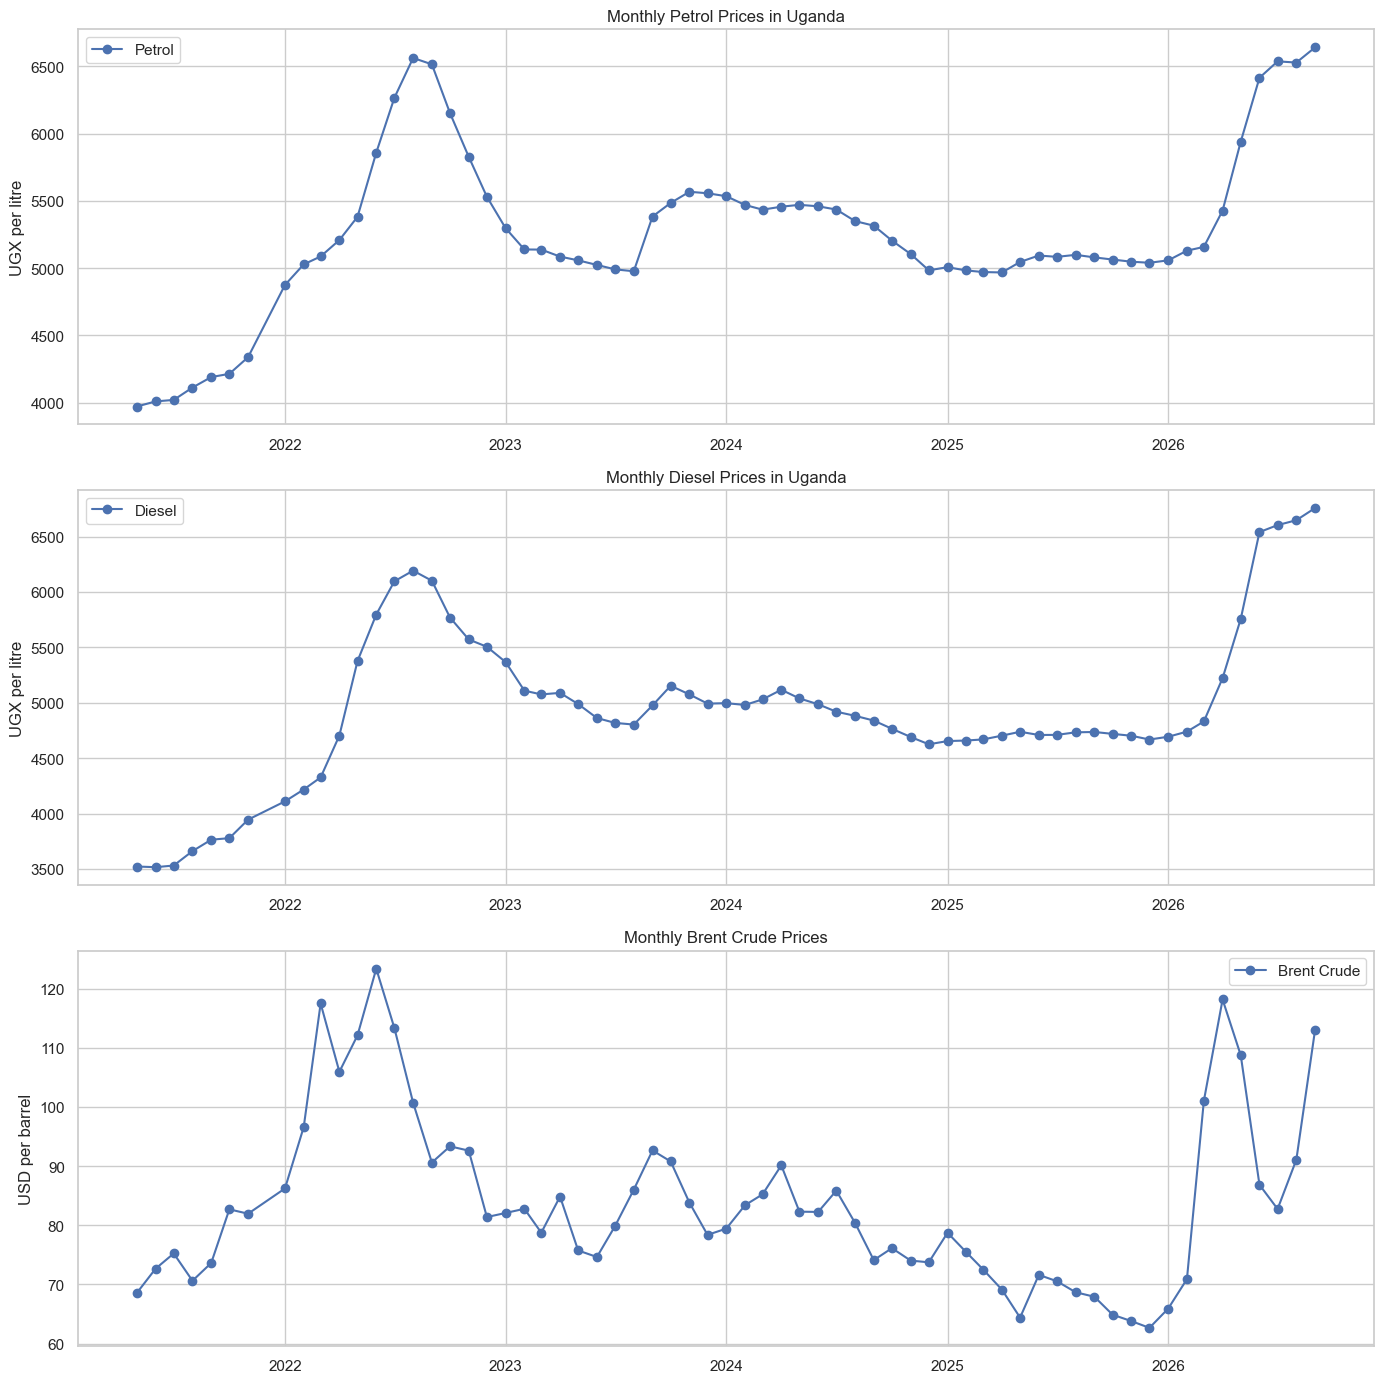

In [28]:
fig, axes = plt.subplots(3, 1, figsize=(14, 14))

# Petrol prices
axes[0].plot(
    master_df["month"],
    master_df["petrol_shs_per_litre"],
    label="Petrol",
    marker="o"
)
axes[0].set_title("Monthly Petrol Prices in Uganda")
axes[0].set_ylabel("UGX per litre")
axes[0].legend()
axes[0].grid(True)

# Diesel prices
axes[1].plot(
    master_df["month"],
    master_df["diesel_shs_per_litre"],
    label="Diesel",
    marker="o"
)
axes[1].set_title("Monthly Diesel Prices in Uganda")
axes[1].set_ylabel("UGX per litre")
axes[1].legend()
axes[1].grid(True)

# Brent crude
axes[2].plot(
    master_df["month"],
    master_df["brent_monthly_avg"],
    label="Brent Crude",
    marker="o"
)
axes[2].set_title("Monthly Brent Crude Prices")
axes[2].set_ylabel("USD per barrel")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [29]:
# Define the processed data directory

processed_dir = os.path.join(project_dir, "data", "processed")

# Create the folder if it does not already exist

os.makedirs(processed_dir, exist_ok=True)

print("Processed folder:", processed_dir)
print("Folder ready!")

Processed folder: C:\Users\CORE !5\Downloads\kampala-fuel-price-predictor\data\processed
Folder ready!


In [30]:
# Define the output file path

master_dataset_path = os.path.join(
    processed_dir,
    "kampala_fuel_master_dataset.csv"
)

# Export master dataset to CSV

master_df.to_csv(
    master_dataset_path,
    index=False
)

print("Master dataset saved successfully!")
print("Saved at:", master_dataset_path)

Master dataset saved successfully!
Saved at: C:\Users\CORE !5\Downloads\kampala-fuel-price-predictor\data\processed\kampala_fuel_master_dataset.csv


In [31]:
# Load the saved CSV to verify it

master_df_check = pd.read_csv(master_dataset_path)

print("Saved dataset dimensions:", master_df_check.shape)

display(master_df_check.head())

print("\nMissing values:")
print(master_df_check.isnull().sum())

Saved dataset dimensions: (64, 5)


,month,petrol_shs_per_litre,diesel_shs_per_litre,brent_monthly_avg,usd_ugx_rate
0,2021-05-01,3971,3522,68.56,"3,545.74"
1,2021-06-01,4009,3516,72.66,"3,556.71"
2,2021-07-01,4020,3531,75.23,"3,549.91"
3,2021-08-01,4112,3661,70.61,"3,535.13"
4,2021-09-01,4190,3764,73.62,"3,542.67"



Missing values:
month                   0
petrol_shs_per_litre    0
diesel_shs_per_litre    0
brent_monthly_avg       0
usd_ugx_rate            0
dtype: int64


In [32]:
# Generate a complete monthly calendar

complete_months = pd.date_range(
    start=master_df["month"].min(),
    end=master_df["month"].max(),
    freq="MS"
)

# Identify months absent from the master dataset

missing_months = complete_months[
    ~complete_months.isin(master_df["month"])
]

print("Expected monthly observations:", len(complete_months))
print("Available observations:", len(master_df))
print("Missing months:", len(missing_months))

print("\nMissing month dates:")

for month in missing_months:
    print(month.strftime("%Y-%m"))

Expected monthly observations: 65
Available observations: 64
Missing months: 1

Missing month dates:
2021-12


In [33]:
# Generate a complete monthly date range

monthly_calendar = pd.DataFrame({
    "month": pd.date_range(
        start=master_df["month"].min(),
        end=master_df["month"].max(),
        freq="MS"
    )
})

# Merge existing observations into the complete calendar

master_df = monthly_calendar.merge(
    master_df,
    on="month",
    how="left"
)

master_df = master_df.sort_values("month").reset_index(drop=True)

print("Updated master dataset:", master_df.shape)

display(
    master_df[
        (master_df["month"] >= "2021-10-01") &
        (master_df["month"] <= "2022-02-01")
    ]
)

Updated master dataset: (65, 5)


,month,petrol_shs_per_litre,diesel_shs_per_litre,brent_monthly_avg,usd_ugx_rate
5,2021-10-01,"4,214.00","3,778.00",82.68,"3,554.78"
6,2021-11-01,"4,338.00","3,945.00",81.94,"3,564.20"
7,2021-12-01,NaN,NaN,NaN,NaN
8,2022-01-01,"4,875.00","4,110.00",86.21,"3,509.86"
9,2022-02-01,"5,028.00","4,217.00",96.59,"3,540.78"


In [34]:
print("Total monthly observations:", len(master_df))

print("\nMissing values:")
print(master_df.isnull().sum())

print("\nDecember 2021:")
display(
    master_df[master_df["month"] == "2021-12-01"]
)

Total monthly observations: 65

Missing values:
month                   0
petrol_shs_per_litre    1
diesel_shs_per_litre    1
brent_monthly_avg       1
usd_ugx_rate            1
dtype: int64

December 2021:


,month,petrol_shs_per_litre,diesel_shs_per_litre,brent_monthly_avg,usd_ugx_rate
7,2021-12-01,NaN,NaN,NaN,NaN


In [35]:
# Investigate December 2021 in each original dataset

target_month = pd.Timestamp("2021-12-01")

print("FUEL PRICE SOURCE")
display(
    fuel_clean[fuel_clean["month"] == target_month]
)

print("\nBRENT CRUDE SOURCE")
display(
    brent_clean[
        brent_clean["Date"].dt.to_period("M") == "2021-12"
    ]
)

print("\nBRENT MONTHLY AGGREGATION")
display(
    brent_monthly[
        brent_monthly["month"] == target_month
    ]
)

print("\nEXCHANGE RATE SOURCE")
display(
    exchange_monthly[
        exchange_monthly["month"] == target_month
    ]
)

FUEL PRICE SOURCE


,month,petrol_shs_per_litre,diesel_shs_per_litre,paraffin_shs_per_litre,petrol_release,diesel_release,paraffin_release



BRENT CRUDE SOURCE


,Date,Price,month
1800,2021-12-03,71.00,2021-12-01
1801,2021-12-10,74.79,2021-12-01
1802,2021-12-17,73.76,2021-12-01
1803,2021-12-24,73.91,2021-12-01
1804,2021-12-31,78.16,2021-12-01



BRENT MONTHLY AGGREGATION


,month,brent_monthly_avg
415,2021-12-01,74.32



EXCHANGE RATE SOURCE


,month,usd_ugx_rate
71,2021-12-01,"3,544.41"


In [36]:
# Restore Brent crude monthly averages

master_df["brent_monthly_avg"] = master_df["month"].map(
    brent_monthly_filtered.set_index("month")["brent_monthly_avg"]
)

# Restore USD/UGX exchange rates

master_df["usd_ugx_rate"] = master_df["month"].map(
    exchange_monthly_filtered.set_index("month")["usd_ugx_rate"]
)

print("External indicators restored!")

External indicators restored!


In [37]:
display(
    master_df[
        master_df["month"] == "2021-12-01"
    ]
)

print("\nMissing values after correction:")
print(master_df.isnull().sum())

,month,petrol_shs_per_litre,diesel_shs_per_litre,brent_monthly_avg,usd_ugx_rate
7,2021-12-01,NaN,NaN,74.32,"3,544.41"



Missing values after correction:
month                   0
petrol_shs_per_litre    1
diesel_shs_per_litre    1
brent_monthly_avg       0
usd_ugx_rate            0
dtype: int64


In [38]:
# Save corrected master dataset

master_dataset_path = os.path.join(
    processed_dir,
    "kampala_fuel_master_dataset.csv"
)

master_df.to_csv(master_dataset_path, index=False)

print("Corrected master dataset saved!")
print("Location:", master_dataset_path)

Corrected master dataset saved!
Location: C:\Users\CORE !5\Downloads\kampala-fuel-price-predictor\data\processed\kampala_fuel_master_dataset.csv


In [39]:
# Create a separate feature engineering dataset

features_df = master_df.copy()

# Petrol price history
features_df["petrol_lag_1"] = features_df["petrol_shs_per_litre"].shift(1)
features_df["petrol_lag_2"] = features_df["petrol_shs_per_litre"].shift(2)

# Diesel price history
features_df["diesel_lag_1"] = features_df["diesel_shs_per_litre"].shift(1)
features_df["diesel_lag_2"] = features_df["diesel_shs_per_litre"].shift(2)

# Brent crude history
features_df["brent_lag_1"] = features_df["brent_monthly_avg"].shift(1)
features_df["brent_lag_2"] = features_df["brent_monthly_avg"].shift(2)

# Exchange rate history
features_df["exchange_lag_1"] = features_df["usd_ugx_rate"].shift(1)
features_df["exchange_lag_2"] = features_df["usd_ugx_rate"].shift(2)

print("Lag features created!")
display(features_df.head(10))

Lag features created!


,month,petrol_shs_per_litre,diesel_shs_per_litre,brent_monthly_avg,usd_ugx_rate,petrol_lag_1,petrol_lag_2,diesel_lag_1,diesel_lag_2,brent_lag_1,brent_lag_2,exchange_lag_1,exchange_lag_2
0,2021-05-01,"3,971.00","3,522.00",68.56,"3,545.74",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2021-06-01,"4,009.00","3,516.00",72.66,"3,556.71","3,971.00",NaN,"3,522.00",NaN,68.56,NaN,"3,545.74",NaN
2,2021-07-01,"4,020.00","3,531.00",75.23,"3,549.91","4,009.00","3,971.00","3,516.00","3,522.00",72.66,68.56,"3,556.71","3,545.74"
3,2021-08-01,"4,112.00","3,661.00",70.61,"3,535.13","4,020.00","4,009.00","3,531.00","3,516.00",75.23,72.66,"3,549.91","3,556.71"
4,2021-09-01,"4,190.00","3,764.00",73.62,"3,542.67","4,112.00","4,020.00","3,661.00","3,531.00",70.61,75.23,"3,535.13","3,549.91"
5,2021-10-01,"4,214.00","3,778.00",82.68,"3,554.78","4,190.00","4,112.00","3,764.00","3,661.00",73.62,70.61,"3,542.67","3,535.13"
6,2021-11-01,"4,338.00","3,945.00",81.94,"3,564.20","4,214.00","4,190.00","3,778.00","3,764.00",82.68,73.62,"3,554.78","3,542.67"
7,2021-12-01,NaN,NaN,74.32,"3,544.41","4,338.00","4,214.00","3,945.00","3,778.00",81.94,82.68,"3,564.20","3,554.78"
8,2022-01-01,"4,875.00","4,110.00",86.21,"3,509.86",NaN,"4,338.00",NaN,"3,945.00",74.32,81.94,"3,544.41","3,564.20"
9,2022-02-01,"5,028.00","4,217.00",96.59,"3,540.78","4,875.00",NaN,"4,110.00",NaN,86.21,74.32,"3,509.86","3,544.41"


In [40]:
# Calculate monthly percentage changes

features_df["brent_change_pct"] = (
    features_df["brent_monthly_avg"].pct_change(fill_method=None) * 100
)

features_df["exchange_change_pct"] = (
    features_df["usd_ugx_rate"].pct_change(fill_method=None) * 100
)

print("Percentage change features created!")

display(
    features_df[[
        "month",
        "brent_monthly_avg",
        "brent_change_pct",
        "usd_ugx_rate",
        "exchange_change_pct"
    ]].head(12)
)

Percentage change features created!


,month,brent_monthly_avg,brent_change_pct,usd_ugx_rate,exchange_change_pct
0,2021-05-01,68.56,NaN,"3,545.74",NaN
1,2021-06-01,72.66,5.99,"3,556.71",0.31
2,2021-07-01,75.23,3.53,"3,549.91",-0.19
3,2021-08-01,70.61,-6.14,"3,535.13",-0.42
4,2021-09-01,73.62,4.26,"3,542.67",0.21
5,2021-10-01,82.68,12.31,"3,554.78",0.34
6,2021-11-01,81.94,-0.89,"3,564.20",0.26
7,2021-12-01,74.32,-9.30,"3,544.41",-0.56
8,2022-01-01,86.21,16.00,"3,509.86",-0.97
9,2022-02-01,96.59,12.04,"3,540.78",0.88


In [41]:
# Historical rolling averages
# Shift(1) ensures we only use information from previous months.

features_df["petrol_ma_3"] = (
    features_df["petrol_shs_per_litre"]
    .shift(1)
    .rolling(window=3)
    .mean()
)

features_df["petrol_ma_6"] = (
    features_df["petrol_shs_per_litre"]
    .shift(1)
    .rolling(window=6)
    .mean()
)

features_df["diesel_ma_3"] = (
    features_df["diesel_shs_per_litre"]
    .shift(1)
    .rolling(window=3)
    .mean()
)

features_df["diesel_ma_6"] = (
    features_df["diesel_shs_per_litre"]
    .shift(1)
    .rolling(window=6)
    .mean()
)

features_df["brent_ma_3"] = (
    features_df["brent_monthly_avg"]
    .shift(1)
    .rolling(window=3)
    .mean()
)

features_df["exchange_ma_3"] = (
    features_df["usd_ugx_rate"]
    .shift(1)
    .rolling(window=3)
    .mean()
)

print("Moving averages created!")

display(features_df.head(12))

Moving averages created!


,month,petrol_shs_per_litre,diesel_shs_per_litre,brent_monthly_avg,usd_ugx_rate,petrol_lag_1,petrol_lag_2,diesel_lag_1,diesel_lag_2,brent_lag_1,brent_lag_2,exchange_lag_1,exchange_lag_2,brent_change_pct,exchange_change_pct,petrol_ma_3,petrol_ma_6,diesel_ma_3,diesel_ma_6,brent_ma_3,exchange_ma_3
0,2021-05-01,"3,971.00","3,522.00",68.56,"3,545.74",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2021-06-01,"4,009.00","3,516.00",72.66,"3,556.71","3,971.00",NaN,"3,522.00",NaN,68.56,NaN,"3,545.74",NaN,5.99,0.31,NaN,NaN,NaN,NaN,NaN,NaN
2,2021-07-01,"4,020.00","3,531.00",75.23,"3,549.91","4,009.00","3,971.00","3,516.00","3,522.00",72.66,68.56,"3,556.71","3,545.74",3.53,-0.19,NaN,NaN,NaN,NaN,NaN,NaN
3,2021-08-01,"4,112.00","3,661.00",70.61,"3,535.13","4,020.00","4,009.00","3,531.00","3,516.00",75.23,72.66,"3,549.91","3,556.71",-6.14,-0.42,"4,000.00",NaN,"3,523.00",NaN,72.15,"3,550.79"
4,2021-09-01,"4,190.00","3,764.00",73.62,"3,542.67","4,112.00","4,020.00","3,661.00","3,531.00",70.61,75.23,"3,535.13","3,549.91",4.26,0.21,"4,047.00",NaN,"3,569.33",NaN,72.83,"3,547.25"
5,2021-10-01,"4,214.00","3,778.00",82.68,"3,554.78","4,190.00","4,112.00","3,764.00","3,661.00",73.62,70.61,"3,542.67","3,535.13",12.31,0.34,"4,107.33",NaN,"3,652.00",NaN,73.15,"3,542.57"
6,2021-11-01,"4,338.00","3,945.00",81.94,"3,564.20","4,214.00","4,190.00","3,778.00","3,764.00",82.68,73.62,"3,554.78","3,542.67",-0.89,0.26,"4,172.00","4,086.00","3,734.33","3,628.67",75.64,"3,544.19"
7,2021-12-01,NaN,NaN,74.32,"3,544.41","4,338.00","4,214.00","3,945.00","3,778.00",81.94,82.68,"3,564.20","3,554.78",-9.30,-0.56,"4,247.33","4,147.17","3,829.00","3,699.17",79.42,"3,553.88"
8,2022-01-01,"4,875.00","4,110.00",86.21,"3,509.86",NaN,"4,338.00",NaN,"3,945.00",74.32,81.94,"3,544.41","3,564.20",16.00,-0.97,NaN,NaN,NaN,NaN,79.65,"3,554.46"
9,2022-02-01,"5,028.00","4,217.00",96.59,"3,540.78","4,875.00",NaN,"4,110.00",NaN,86.21,74.32,"3,509.86","3,544.41",12.04,0.88,NaN,NaN,NaN,NaN,80.83,"3,539.49"


In [42]:
# Extract calendar information

features_df["year"] = features_df["month"].dt.year

features_df["month_number"] = features_df["month"].dt.month

# Encode month as seasonal variables

features_df["month_sin"] = np.sin(
    2 * np.pi * features_df["month_number"] / 12
)

features_df["month_cos"] = np.cos(
    2 * np.pi * features_df["month_number"] / 12
)

print("Calendar features created!")

display(
    features_df[[
        "month",
        "year",
        "month_number",
        "month_sin",
        "month_cos"
    ]].head(12)
)

Calendar features created!


,month,year,month_number,month_sin,month_cos
0,2021-05-01,2021,5,0.50,-0.87
1,2021-06-01,2021,6,0.00,-1.00
2,2021-07-01,2021,7,-0.50,-0.87
3,2021-08-01,2021,8,-0.87,-0.50
4,2021-09-01,2021,9,-1.00,-0.00
5,2021-10-01,2021,10,-0.87,0.50
6,2021-11-01,2021,11,-0.50,0.87
7,2021-12-01,2021,12,-0.00,1.00
8,2022-01-01,2022,1,0.50,0.87
9,2022-02-01,2022,2,0.87,0.50


In [43]:
# Create next-month prediction targets

features_df["next_month_petrol"] = (
    features_df["petrol_shs_per_litre"].shift(-1)
)

features_df["next_month_diesel"] = (
    features_df["diesel_shs_per_litre"].shift(-1)
)

print("Prediction targets created!")

display(
    features_df[[
        "month",
        "petrol_shs_per_litre",
        "next_month_petrol",
        "diesel_shs_per_litre",
        "next_month_diesel"
    ]].head(12)
)

Prediction targets created!


,month,petrol_shs_per_litre,next_month_petrol,diesel_shs_per_litre,next_month_diesel
0,2021-05-01,"3,971.00","4,009.00","3,522.00","3,516.00"
1,2021-06-01,"4,009.00","4,020.00","3,516.00","3,531.00"
2,2021-07-01,"4,020.00","4,112.00","3,531.00","3,661.00"
3,2021-08-01,"4,112.00","4,190.00","3,661.00","3,764.00"
4,2021-09-01,"4,190.00","4,214.00","3,764.00","3,778.00"
5,2021-10-01,"4,214.00","4,338.00","3,778.00","3,945.00"
6,2021-11-01,"4,338.00",NaN,"3,945.00",NaN
7,2021-12-01,NaN,"4,875.00",NaN,"4,110.00"
8,2022-01-01,"4,875.00","5,028.00","4,110.00","4,217.00"
9,2022-02-01,"5,028.00","5,087.00","4,217.00","4,326.00"


In [44]:
print("ENGINEERED DATASET DIMENSIONS")
print(features_df.shape)

print("\nALL COLUMN NAMES")

for column in features_df.columns:
    print(column)

print("\nMISSING VALUES")
print(features_df.isnull().sum())

ENGINEERED DATASET DIMENSIONS
(65, 27)

ALL COLUMN NAMES
month
petrol_shs_per_litre
diesel_shs_per_litre
brent_monthly_avg
usd_ugx_rate
petrol_lag_1
petrol_lag_2
diesel_lag_1
diesel_lag_2
brent_lag_1
brent_lag_2
exchange_lag_1
exchange_lag_2
brent_change_pct
exchange_change_pct
petrol_ma_3
petrol_ma_6
diesel_ma_3
diesel_ma_6
brent_ma_3
exchange_ma_3
year
month_number
month_sin
month_cos
next_month_petrol
next_month_diesel

MISSING VALUES
month                    0
petrol_shs_per_litre     1
diesel_shs_per_litre     1
brent_monthly_avg        0
usd_ugx_rate             0
petrol_lag_1             2
petrol_lag_2             3
diesel_lag_1             2
diesel_lag_2             3
brent_lag_1              1
brent_lag_2              2
exchange_lag_1           1
exchange_lag_2           2
brent_change_pct         1
exchange_change_pct      1
petrol_ma_3              6
petrol_ma_6             12
diesel_ma_3              6
diesel_ma_6             12
brent_ma_3               3
exchange_ma_3     

In [45]:
# Define output path

features_path = os.path.join(
    processed_dir,
    "kampala_fuel_engineered_dataset.csv"
)

# Save engineered dataset

features_df.to_csv(features_path, index=False)

print("Engineered dataset saved successfully!")
print("Location:", features_path)

Engineered dataset saved successfully!
Location: C:\Users\CORE !5\Downloads\kampala-fuel-price-predictor\data\processed\kampala_fuel_engineered_dataset.csv


In [46]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=master_df["month"],
    y=master_df["petrol_shs_per_litre"],
    mode="lines+markers",
    name="Petrol"
))

fig.add_trace(go.Scatter(
    x=master_df["month"],
    y=master_df["diesel_shs_per_litre"],
    mode="lines+markers",
    name="Diesel"
))

fig.update_layout(
    title="Uganda Monthly Petrol vs Diesel Prices",
    xaxis_title="Month",
    yaxis_title="Price (UGX per litre)",
    template="plotly_white",
    hovermode="x unified"
)

fig.show()

In [47]:
fig = px.line(
    master_df,
    x="month",
    y="brent_monthly_avg",
    markers=True,
    title="Monthly Brent Crude Oil Prices"
)

fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Brent Price (USD per barrel)",
    template="plotly_white"
)

fig.show()

In [48]:
fig = px.scatter(
    master_df.dropna(
        subset=["brent_monthly_avg", "petrol_shs_per_litre"]
    ),
    x="brent_monthly_avg",
    y="petrol_shs_per_litre",
    trendline="ols",
    hover_data=["month"],
    title="Relationship Between Brent Crude and Petrol Prices"
)

fig.update_layout(
    xaxis_title="Brent Crude (USD per barrel)",
    yaxis_title="Petrol Price (UGX per litre)",
    template="plotly_white"
)

fig.show()

In [49]:
fig = make_subplots(
    rows=2,
    cols=1,
    subplot_titles=(
        "USD/UGX Exchange Rate vs Petrol Price",
        "USD/UGX Exchange Rate vs Diesel Price"
    )
)

fig.add_trace(
    go.Scatter(
        x=master_df["usd_ugx_rate"],
        y=master_df["petrol_shs_per_litre"],
        mode="markers",
        name="Petrol"
    ),
    row=1,
    col=1
)

fig.add_trace(
    go.Scatter(
        x=master_df["usd_ugx_rate"],
        y=master_df["diesel_shs_per_litre"],
        mode="markers",
        name="Diesel"
    ),
    row=2,
    col=1
)

fig.update_xaxes(title_text="USD/UGX Exchange Rate", row=1, col=1)
fig.update_xaxes(title_text="USD/UGX Exchange Rate", row=2, col=1)

fig.update_yaxes(title_text="Petrol (UGX/litre)", row=1, col=1)
fig.update_yaxes(title_text="Diesel (UGX/litre)", row=2, col=1)

fig.update_layout(
    title="Exchange Rate and Local Fuel Prices",
    template="plotly_white",
    height=750
)

fig.show()

In [50]:
correlation_columns = [
    "petrol_shs_per_litre",
    "diesel_shs_per_litre",
    "brent_monthly_avg",
    "usd_ugx_rate"
]

correlation_matrix = master_df[
    correlation_columns
].corr(method="pearson")

display(correlation_matrix)

,petrol_shs_per_litre,diesel_shs_per_litre,brent_monthly_avg,usd_ugx_rate
petrol_shs_per_litre,1.00,0.97,0.51,0.70
diesel_shs_per_litre,0.97,1.00,0.48,0.69
brent_monthly_avg,0.51,0.48,1.00,0.48
usd_ugx_rate,0.70,0.69,0.48,1.00


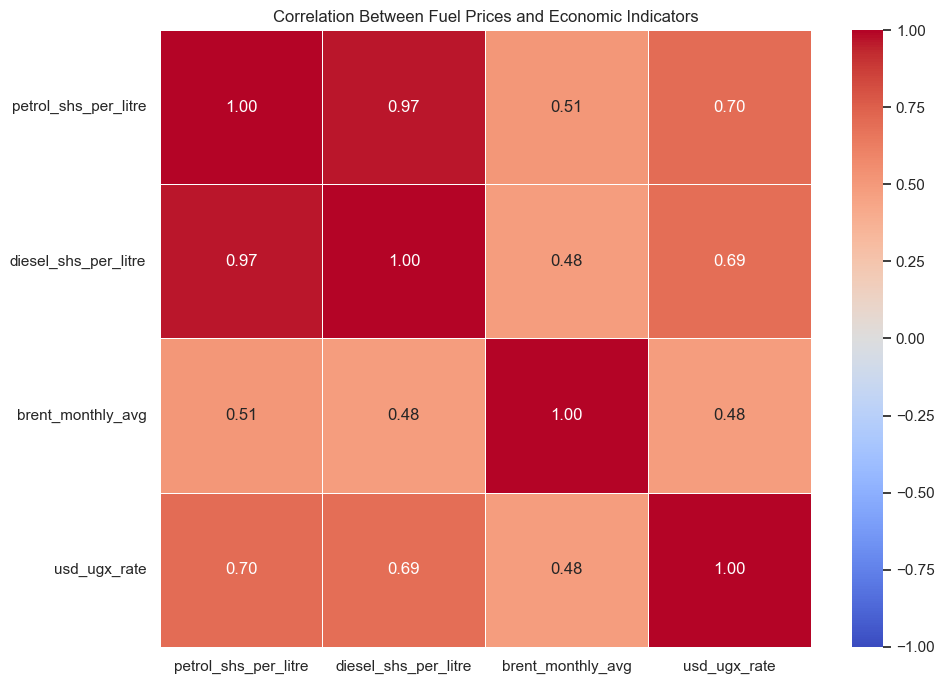

In [51]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Fuel Prices and Economic Indicators")
plt.tight_layout()
plt.show()

In [52]:
lag_results = []

for lag in range(0, 7):

    temp = master_df.copy()

    temp["brent_previous"] = (
        temp["brent_monthly_avg"].shift(lag)
    )

    petrol_corr = temp[
        ["petrol_shs_per_litre", "brent_previous"]
    ].corr().iloc[0, 1]

    diesel_corr = temp[
        ["diesel_shs_per_litre", "brent_previous"]
    ].corr().iloc[0, 1]

    lag_results.append({
        "brent_lag_months": lag,
        "petrol_correlation": petrol_corr,
        "diesel_correlation": diesel_corr
    })

lag_correlation_df = pd.DataFrame(lag_results)

display(lag_correlation_df)

,brent_lag_months,petrol_correlation,diesel_correlation
0,0,0.51,0.48
1,1,0.62,0.59
2,2,0.72,0.70
3,3,0.74,0.72
4,4,0.68,0.66
5,5,0.52,0.51
6,6,0.26,0.29


In [53]:
correlation_path = os.path.join(
    processed_dir,
    "fuel_price_correlation_matrix.csv"
)

lag_correlation_path = os.path.join(
    processed_dir,
    "brent_lag_correlation_analysis.csv"
)

correlation_matrix.to_csv(correlation_path)

lag_correlation_df.to_csv(
    lag_correlation_path,
    index=False
)

print("EDA results saved successfully!")
print(correlation_path)
print(lag_correlation_path)

EDA results saved successfully!
C:\Users\CORE !5\Downloads\kampala-fuel-price-predictor\data\processed\fuel_price_correlation_matrix.csv
C:\Users\CORE !5\Downloads\kampala-fuel-price-predictor\data\processed\brent_lag_correlation_analysis.csv


In [54]:
display(
    lag_correlation_df.style
    .format({
        "petrol_correlation": "{:.3f}",
        "diesel_correlation": "{:.3f}"
    })
)

,brent_lag_months,petrol_correlation,diesel_correlation
0,0,0.509,0.480
1,1,0.617,0.590
2,2,0.717,0.698
3,3,0.743,0.721
4,4,0.678,0.656
5,5,0.522,0.510
6,6,0.259,0.286


In [55]:
lag_results = []

for lag in range(7):
    temp = master_df.copy()

    temp["brent_previous"] = temp["brent_monthly_avg"].shift(lag)

    petrol_data = temp[["petrol_shs_per_litre", "brent_previous"]].dropna()
    diesel_data = temp[["diesel_shs_per_litre", "brent_previous"]].dropna()

    lag_results.append({
        "brent_lag_months": lag,
        "petrol_correlation": petrol_data["petrol_shs_per_litre"].corr(
            petrol_data["brent_previous"]
        ),
        "diesel_correlation": diesel_data["diesel_shs_per_litre"].corr(
            diesel_data["brent_previous"]
        ),
        "petrol_observations": len(petrol_data),
        "diesel_observations": len(diesel_data)
    })

lag_correlation_df = pd.DataFrame(lag_results)

display(lag_correlation_df.round(3))

,brent_lag_months,petrol_correlation,diesel_correlation,petrol_observations,diesel_observations
0,0,0.51,0.48,64,64
1,1,0.62,0.59,63,63
2,2,0.72,0.70,62,62
3,3,0.74,0.72,61,61
4,4,0.68,0.66,60,60
5,5,0.52,0.51,59,59
6,6,0.26,0.29,58,58


In [56]:
# Create a separate copy for machine learning
model_df = features_df.copy()

# Add the third-month Brent lag
model_df["brent_lag_3"] = model_df["brent_monthly_avg"].shift(3)

# Select features for petrol prediction
petrol_features = [
    "petrol_shs_per_litre",
    "brent_monthly_avg",
    "brent_lag_1",
    "brent_lag_2",
    "brent_lag_3",
    "usd_ugx_rate"
]

# Select features for diesel prediction
diesel_features = [
    "diesel_shs_per_litre",
    "brent_monthly_avg",
    "brent_lag_1",
    "brent_lag_2",
    "brent_lag_3",
    "usd_ugx_rate"
]

# Create separate datasets
petrol_model_df = model_df[
    ["month"] + petrol_features + ["next_month_petrol"]
].dropna().copy()

diesel_model_df = model_df[
    ["month"] + diesel_features + ["next_month_diesel"]
].dropna().copy()

print("PETROL MODEL DATA")
print("Shape:", petrol_model_df.shape)
print("Date range:", petrol_model_df["month"].min(), "to",
      petrol_model_df["month"].max())

print("\nDIESEL MODEL DATA")
print("Shape:", diesel_model_df.shape)
print("Date range:", diesel_model_df["month"].min(), "to",
      diesel_model_df["month"].max())

PETROL MODEL DATA
Shape: (59, 8)
Date range: 2021-08-01 00:00:00 to 2026-08-01 00:00:00

DIESEL MODEL DATA
Shape: (59, 8)
Date range: 2021-08-01 00:00:00 to 2026-08-01 00:00:00


In [57]:
# Reserve the last 12 observations for testing
test_size = 12

# -----------------------------
# PETROL MODEL
# -----------------------------

split_index_petrol = len(petrol_model_df) - test_size

petrol_train = petrol_model_df.iloc[:split_index_petrol].copy()
petrol_test = petrol_model_df.iloc[split_index_petrol:].copy()

X_train_petrol = petrol_train[petrol_features]
X_test_petrol = petrol_test[petrol_features]

y_train_petrol = petrol_train["next_month_petrol"]
y_test_petrol = petrol_test["next_month_petrol"]


# -----------------------------
# DIESEL MODEL
# -----------------------------

split_index_diesel = len(diesel_model_df) - test_size

diesel_train = diesel_model_df.iloc[:split_index_diesel].copy()
diesel_test = diesel_model_df.iloc[split_index_diesel:].copy()

X_train_diesel = diesel_train[diesel_features]
X_test_diesel = diesel_test[diesel_features]

y_train_diesel = diesel_train["next_month_diesel"]
y_test_diesel = diesel_test["next_month_diesel"]


# -----------------------------
# DISPLAY RESULTS
# -----------------------------

print("PETROL MODEL")
print("Training observations:", len(X_train_petrol))
print("Testing observations:", len(X_test_petrol))
print("Training period:", petrol_train["month"].min(), "to",
      petrol_train["month"].max())
print("Testing period:", petrol_test["month"].min(), "to",
      petrol_test["month"].max())

print("\nDIESEL MODEL")
print("Training observations:", len(X_train_diesel))
print("Testing observations:", len(X_test_diesel))
print("Training period:", diesel_train["month"].min(), "to",
      diesel_train["month"].max())
print("Testing period:", diesel_test["month"].min(), "to",
      diesel_test["month"].max())

PETROL MODEL
Training observations: 47
Testing observations: 12
Training period: 2021-08-01 00:00:00 to 2025-08-01 00:00:00
Testing period: 2025-09-01 00:00:00 to 2026-08-01 00:00:00

DIESEL MODEL
Training observations: 47
Testing observations: 12
Training period: 2021-08-01 00:00:00 to 2025-08-01 00:00:00
Testing period: 2025-09-01 00:00:00 to 2026-08-01 00:00:00


In [58]:
# Petrol baseline predictions
petrol_baseline_predictions = X_test_petrol[
    "petrol_shs_per_litre"
].values

# Diesel baseline predictions
diesel_baseline_predictions = X_test_diesel[
    "diesel_shs_per_litre"
].values


# Evaluate baseline performance
petrol_baseline_mae = mean_absolute_error(
    y_test_petrol,
    petrol_baseline_predictions
)

diesel_baseline_mae = mean_absolute_error(
    y_test_diesel,
    diesel_baseline_predictions
)


print("BASELINE MODEL PERFORMANCE")
print("--------------------------------")
print(f"Petrol MAE: UGX {petrol_baseline_mae:,.2f}")
print(f"Diesel MAE: UGX {diesel_baseline_mae:,.2f}")

BASELINE MODEL PERFORMANCE
--------------------------------
Petrol MAE: UGX 138.33
Diesel MAE: UGX 179.75


In [59]:
# Create petrol Linear Regression model
petrol_lr = LinearRegression()

# Train petrol model
petrol_lr.fit(X_train_petrol, y_train_petrol)

# Predict petrol prices
petrol_lr_predictions = petrol_lr.predict(X_test_petrol)


# Create diesel Linear Regression model
diesel_lr = LinearRegression()

# Train diesel model
diesel_lr.fit(X_train_diesel, y_train_diesel)

# Predict diesel prices
diesel_lr_predictions = diesel_lr.predict(X_test_diesel)


# Calculate MAE
petrol_lr_mae = mean_absolute_error(
    y_test_petrol,
    petrol_lr_predictions
)

diesel_lr_mae = mean_absolute_error(
    y_test_diesel,
    diesel_lr_predictions
)


# Display results
print("LINEAR REGRESSION PERFORMANCE")
print("--------------------------------")
print(f"Petrol MAE: UGX {petrol_lr_mae:,.2f}")
print(f"Diesel MAE: UGX {diesel_lr_mae:,.2f}")

LINEAR REGRESSION PERFORMANCE
--------------------------------
Petrol MAE: UGX 192.24
Diesel MAE: UGX 195.03


In [60]:
# Create petrol Random Forest model
petrol_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    min_samples_leaf=3,
    random_state=42
)

# Train petrol model
petrol_rf.fit(X_train_petrol, y_train_petrol)

# Predict petrol prices
petrol_rf_predictions = petrol_rf.predict(X_test_petrol)


# Create diesel Random Forest model
diesel_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    min_samples_leaf=3,
    random_state=42
)

# Train diesel model
diesel_rf.fit(X_train_diesel, y_train_diesel)

# Predict diesel prices
diesel_rf_predictions = diesel_rf.predict(X_test_diesel)


# Calculate MAE
petrol_rf_mae = mean_absolute_error(
    y_test_petrol,
    petrol_rf_predictions
)

diesel_rf_mae = mean_absolute_error(
    y_test_diesel,
    diesel_rf_predictions
)


# Display results
print("RANDOM FOREST PERFORMANCE")
print("--------------------------------")
print(f"Petrol MAE: UGX {petrol_rf_mae:,.2f}")
print(f"Diesel MAE: UGX {diesel_rf_mae:,.2f}")

RANDOM FOREST PERFORMANCE
--------------------------------
Petrol MAE: UGX 294.15
Diesel MAE: UGX 466.51


In [61]:
# Petrol prediction comparison
petrol_results = pd.DataFrame({
    "Month": petrol_test["month"].values,
    "Actual_Price": y_test_petrol.values,
    "Baseline_Prediction": petrol_baseline_predictions,
    "Linear_Regression": petrol_lr_predictions,
    "Random_Forest": petrol_rf_predictions
})

# Diesel prediction comparison
diesel_results = pd.DataFrame({
    "Month": diesel_test["month"].values,
    "Actual_Price": y_test_diesel.values,
    "Baseline_Prediction": diesel_baseline_predictions,
    "Linear_Regression": diesel_lr_predictions,
    "Random_Forest": diesel_rf_predictions
})

print("PETROL PREDICTION COMPARISON")
display(petrol_results.round(2))

print("DIESEL PREDICTION COMPARISON")
display(diesel_results.round(2))

PETROL PREDICTION COMPARISON


,Month,Actual_Price,Baseline_Prediction,Linear_Regression,Random_Forest
0,2025-09-01,"5,064.00","5,080.00","4,935.47","4,963.90"
1,2025-10-01,"5,048.00","5,064.00","4,891.97","4,962.67"
2,2025-11-01,"5,040.00","5,048.00","4,920.64","5,034.90"
3,2025-12-01,"5,058.00","5,040.00","4,893.54","5,034.52"
4,2026-01-01,"5,130.00","5,058.00","4,932.88","5,007.78"
5,2026-02-01,"5,158.00","5,130.00","5,049.63","5,038.78"
6,2026-03-01,"5,428.00","5,158.00","5,406.86","5,094.74"
7,2026-04-01,"5,940.00","5,428.00","5,791.89","5,536.34"
8,2026-05-01,"6,416.00","5,940.00","6,220.71","5,933.39"
9,2026-06-01,"6,538.00","6,416.00","6,246.56","6,065.70"


DIESEL PREDICTION COMPARISON


,Month,Actual_Price,Baseline_Prediction,Linear_Regression,Random_Forest
0,2025-09-01,"4,719.00","4,736.00","4,673.82","4,557.93"
1,2025-10-01,"4,702.00","4,719.00","4,640.21","4,557.93"
2,2025-11-01,"4,668.00","4,702.00","4,586.63","4,720.56"
3,2025-12-01,"4,693.00","4,668.00","4,549.31","4,707.11"
4,2026-01-01,"4,739.00","4,693.00","4,615.40","4,604.00"
5,2026-02-01,"4,831.00","4,739.00","4,715.04","4,727.17"
6,2026-03-01,"5,222.00","4,831.00","5,035.96","4,886.42"
7,2026-04-01,"5,756.00","5,222.00","5,675.02","5,076.66"
8,2026-05-01,"6,540.00","5,756.00","6,124.76","5,594.93"
9,2026-06-01,"6,603.00","6,540.00","6,409.08","5,811.11"


In [62]:
# Recalculate metrics directly from the prediction tables

for name, results in [
    ("PETROL", petrol_results),
    ("DIESEL", diesel_results)
]:
    print(f"\n{name} MODEL")

    for column in [
        "Baseline_Prediction",
        "Linear_Regression",
        "Random_Forest"
    ]:
        mae = mean_absolute_error(
            results["Actual_Price"],
            results[column]
        )

        print(f"{column}: UGX {mae:,.2f}")


PETROL MODEL
Baseline_Prediction: UGX 138.33
Linear_Regression: UGX 192.24
Random_Forest: UGX 294.15

DIESEL MODEL
Baseline_Prediction: UGX 179.75
Linear_Regression: UGX 195.03
Random_Forest: UGX 466.51


In [63]:
print("PETROL RESULTS")
display(petrol_results.round(2))

print("\nDIESEL RESULTS")
display(diesel_results.round(2))

PETROL RESULTS


,Month,Actual_Price,Baseline_Prediction,Linear_Regression,Random_Forest
0,2025-09-01,"5,064.00","5,080.00","4,935.47","4,963.90"
1,2025-10-01,"5,048.00","5,064.00","4,891.97","4,962.67"
2,2025-11-01,"5,040.00","5,048.00","4,920.64","5,034.90"
3,2025-12-01,"5,058.00","5,040.00","4,893.54","5,034.52"
4,2026-01-01,"5,130.00","5,058.00","4,932.88","5,007.78"
5,2026-02-01,"5,158.00","5,130.00","5,049.63","5,038.78"
6,2026-03-01,"5,428.00","5,158.00","5,406.86","5,094.74"
7,2026-04-01,"5,940.00","5,428.00","5,791.89","5,536.34"
8,2026-05-01,"6,416.00","5,940.00","6,220.71","5,933.39"
9,2026-06-01,"6,538.00","6,416.00","6,246.56","6,065.70"



DIESEL RESULTS


,Month,Actual_Price,Baseline_Prediction,Linear_Regression,Random_Forest
0,2025-09-01,"4,719.00","4,736.00","4,673.82","4,557.93"
1,2025-10-01,"4,702.00","4,719.00","4,640.21","4,557.93"
2,2025-11-01,"4,668.00","4,702.00","4,586.63","4,720.56"
3,2025-12-01,"4,693.00","4,668.00","4,549.31","4,707.11"
4,2026-01-01,"4,739.00","4,693.00","4,615.40","4,604.00"
5,2026-02-01,"4,831.00","4,739.00","4,715.04","4,727.17"
6,2026-03-01,"5,222.00","4,831.00","5,035.96","4,886.42"
7,2026-04-01,"5,756.00","5,222.00","5,675.02","5,076.66"
8,2026-05-01,"6,540.00","5,756.00","6,124.76","5,594.93"
9,2026-06-01,"6,603.00","6,540.00","6,409.08","5,811.11"


In [64]:
print("PETROL RESULTS — first five rows")
display(petrol_results.head())

print("DIESEL RESULTS — first five rows")
display(diesel_results.head())

PETROL RESULTS — first five rows


,Month,Actual_Price,Baseline_Prediction,Linear_Regression,Random_Forest
0,2025-09-01,"5,064.00","5,080.00","4,935.47","4,963.90"
1,2025-10-01,"5,048.00","5,064.00","4,891.97","4,962.67"
2,2025-11-01,"5,040.00","5,048.00","4,920.64","5,034.90"
3,2025-12-01,"5,058.00","5,040.00","4,893.54","5,034.52"
4,2026-01-01,"5,130.00","5,058.00","4,932.88","5,007.78"


DIESEL RESULTS — first five rows


,Month,Actual_Price,Baseline_Prediction,Linear_Regression,Random_Forest
0,2025-09-01,"4,719.00","4,736.00","4,673.82","4,557.93"
1,2025-10-01,"4,702.00","4,719.00","4,640.21","4,557.93"
2,2025-11-01,"4,668.00","4,702.00","4,586.63","4,720.56"
3,2025-12-01,"4,693.00","4,668.00","4,549.31","4,707.11"
4,2026-01-01,"4,739.00","4,693.00","4,615.40","4,604.00"


In [65]:
# Correct PETROL results
petrol_results = pd.DataFrame({
    "Month": petrol_test["month"].values,
    "Actual_Price": y_test_petrol.values,
    "Baseline_Prediction": petrol_baseline_predictions,
    "Linear_Regression": petrol_lr_predictions,
    "Random_Forest": petrol_rf_predictions
})

# Correct DIESEL results
diesel_results = pd.DataFrame({
    "Month": diesel_test["month"].values,
    "Actual_Price": y_test_diesel.values,
    "Baseline_Prediction": diesel_baseline_predictions,
    "Linear_Regression": diesel_lr_predictions,
    "Random_Forest": diesel_rf_predictions
})

print("PETROL RESULTS")
display(petrol_results.head())

print("DIESEL RESULTS")
display(diesel_results.head())

PETROL RESULTS


,Month,Actual_Price,Baseline_Prediction,Linear_Regression,Random_Forest
0,2025-09-01,"5,064.00","5,080.00","4,935.47","4,963.90"
1,2025-10-01,"5,048.00","5,064.00","4,891.97","4,962.67"
2,2025-11-01,"5,040.00","5,048.00","4,920.64","5,034.90"
3,2025-12-01,"5,058.00","5,040.00","4,893.54","5,034.52"
4,2026-01-01,"5,130.00","5,058.00","4,932.88","5,007.78"


DIESEL RESULTS


,Month,Actual_Price,Baseline_Prediction,Linear_Regression,Random_Forest
0,2025-09-01,"4,719.00","4,736.00","4,673.82","4,557.93"
1,2025-10-01,"4,702.00","4,719.00","4,640.21","4,557.93"
2,2025-11-01,"4,668.00","4,702.00","4,586.63","4,720.56"
3,2025-12-01,"4,693.00","4,668.00","4,549.31","4,707.11"
4,2026-01-01,"4,739.00","4,693.00","4,615.40","4,604.00"


In [66]:
for name, results in [
    ("PETROL", petrol_results),
    ("DIESEL", diesel_results)
]:
    print(f"\n{name} MODEL")

    for column in [
        "Baseline_Prediction",
        "Linear_Regression",
        "Random_Forest"
    ]:
        mae = mean_absolute_error(
            results["Actual_Price"],
            results[column]
        )

        print(f"{column}: UGX {mae:,.2f}")


PETROL MODEL
Baseline_Prediction: UGX 138.33
Linear_Regression: UGX 192.24
Random_Forest: UGX 294.15

DIESEL MODEL
Baseline_Prediction: UGX 179.75
Linear_Regression: UGX 195.03
Random_Forest: UGX 466.51


In [67]:
print("PETROL TEST DATA")
print("Actual first price:", y_test_petrol.iloc[0])
print("Baseline first prediction:", petrol_baseline_predictions[0])

print("\nDIESEL TEST DATA")
print("Actual first price:", y_test_diesel.iloc[0])
print("Baseline first prediction:", diesel_baseline_predictions[0])

print("\nRESULT TABLES")
print("Petrol first actual:", petrol_results["Actual_Price"].iloc[0])
print("Diesel first actual:", diesel_results["Actual_Price"].iloc[0])

PETROL TEST DATA
Actual first price: 5064.0
Baseline first prediction: 5080.0

DIESEL TEST DATA
Actual first price: 4719.0
Baseline first prediction: 4736.0

RESULT TABLES
Petrol first actual: 5064.0
Diesel first actual: 4719.0


In [68]:
print("PETROL MODEL DATASET")
display(petrol_model_df[
    ["month", "petrol_shs_per_litre", "next_month_petrol"]
].head())

print("\nDIESEL MODEL DATASET")
display(diesel_model_df[
    ["month", "diesel_shs_per_litre", "next_month_diesel"]
].head())

PETROL MODEL DATASET


,month,petrol_shs_per_litre,next_month_petrol
3,2021-08-01,"4,112.00","4,190.00"
4,2021-09-01,"4,190.00","4,214.00"
5,2021-10-01,"4,214.00","4,338.00"
8,2022-01-01,"4,875.00","5,028.00"
9,2022-02-01,"5,028.00","5,087.00"



DIESEL MODEL DATASET


,month,diesel_shs_per_litre,next_month_diesel
3,2021-08-01,"3,661.00","3,764.00"
4,2021-09-01,"3,764.00","3,778.00"
5,2021-10-01,"3,778.00","3,945.00"
8,2022-01-01,"4,110.00","4,217.00"
9,2022-02-01,"4,217.00","4,326.00"


In [69]:
print("PETROL TEST DATASET")
display(petrol_test.head(3))

print("\nDIESEL TEST DATASET")
display(diesel_test.head(3))

PETROL TEST DATASET


,month,petrol_shs_per_litre,brent_monthly_avg,brent_lag_1,brent_lag_2,brent_lag_3,usd_ugx_rate,next_month_petrol
52,2025-09-01,"5,080.00",67.91,68.67,70.53,71.61,"3,490.00","5,064.00"
53,2025-10-01,"5,064.00",64.88,67.91,68.67,70.53,"3,478.95","5,048.00"
54,2025-11-01,"5,048.00",63.80,64.88,67.91,68.67,"3,630.09","5,040.00"



DIESEL TEST DATASET


,month,diesel_shs_per_litre,brent_monthly_avg,brent_lag_1,brent_lag_2,brent_lag_3,usd_ugx_rate,next_month_diesel
52,2025-09-01,"4,736.00",67.91,68.67,70.53,71.61,"3,490.00","4,719.00"
53,2025-10-01,"4,719.00",64.88,67.91,68.67,70.53,"3,478.95","4,702.00"
54,2025-11-01,"4,702.00",63.80,64.88,67.91,68.67,"3,630.09","4,668.00"


In [70]:
# Rebuild model dataset
model_df = features_df.copy()

# Create Brent lag 3
model_df["brent_lag_3"] = model_df["brent_monthly_avg"].shift(3)

# Define features
petrol_features = [
    "petrol_shs_per_litre",
    "brent_monthly_avg",
    "brent_lag_1",
    "brent_lag_2",
    "brent_lag_3",
    "usd_ugx_rate"
]

diesel_features = [
    "diesel_shs_per_litre",
    "brent_monthly_avg",
    "brent_lag_1",
    "brent_lag_2",
    "brent_lag_3",
    "usd_ugx_rate"
]

# Rebuild petrol dataset
petrol_model_df = model_df[
    ["month"] + petrol_features + ["next_month_petrol"]
].dropna().copy()

# Rebuild diesel dataset
diesel_model_df = model_df[
    ["month"] + diesel_features + ["next_month_diesel"]
].dropna().copy()

# Sort chronologically
petrol_model_df = petrol_model_df.sort_values("month").reset_index(drop=True)
diesel_model_df = diesel_model_df.sort_values("month").reset_index(drop=True)

# Chronological train/test split
test_size = 12

petrol_split = len(petrol_model_df) - test_size
diesel_split = len(diesel_model_df) - test_size

petrol_train = petrol_model_df.iloc[:petrol_split].copy()
petrol_test = petrol_model_df.iloc[petrol_split:].copy()

diesel_train = diesel_model_df.iloc[:diesel_split].copy()
diesel_test = diesel_model_df.iloc[diesel_split:].copy()

# Separate features and targets
X_train_petrol = petrol_train[petrol_features]
X_test_petrol = petrol_test[petrol_features]

y_train_petrol = petrol_train["next_month_petrol"]
y_test_petrol = petrol_test["next_month_petrol"]

X_train_diesel = diesel_train[diesel_features]
X_test_diesel = diesel_test[diesel_features]

y_train_diesel = diesel_train["next_month_diesel"]
y_test_diesel = diesel_test["next_month_diesel"]

print("PETROL TEST DATA")
display(petrol_test.head(3))

print("DIESEL TEST DATA")
display(diesel_test.head(3))

PETROL TEST DATA


,month,petrol_shs_per_litre,brent_monthly_avg,brent_lag_1,brent_lag_2,brent_lag_3,usd_ugx_rate,next_month_petrol
47,2025-09-01,"5,080.00",67.91,68.67,70.53,71.61,"3,490.00","5,064.00"
48,2025-10-01,"5,064.00",64.88,67.91,68.67,70.53,"3,478.95","5,048.00"
49,2025-11-01,"5,048.00",63.80,64.88,67.91,68.67,"3,630.09","5,040.00"


DIESEL TEST DATA


,month,diesel_shs_per_litre,brent_monthly_avg,brent_lag_1,brent_lag_2,brent_lag_3,usd_ugx_rate,next_month_diesel
47,2025-09-01,"4,736.00",67.91,68.67,70.53,71.61,"3,490.00","4,719.00"
48,2025-10-01,"4,719.00",64.88,67.91,68.67,70.53,"3,478.95","4,702.00"
49,2025-11-01,"4,702.00",63.80,64.88,67.91,68.67,"3,630.09","4,668.00"


In [71]:
# 1. Train Linear Regression models
petrol_lr = LinearRegression()
petrol_lr.fit(X_train_petrol, y_train_petrol)

diesel_lr = LinearRegression()
diesel_lr.fit(X_train_diesel, y_train_diesel)


# 2. Train Random Forest models
petrol_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    min_samples_leaf=3,
    random_state=42
)

diesel_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    min_samples_leaf=3,
    random_state=42
)

petrol_rf.fit(X_train_petrol, y_train_petrol)
diesel_rf.fit(X_train_diesel, y_train_diesel)


# 3. Generate predictions
petrol_lr_predictions = petrol_lr.predict(X_test_petrol)
diesel_lr_predictions = diesel_lr.predict(X_test_diesel)

petrol_rf_predictions = petrol_rf.predict(X_test_petrol)
diesel_rf_predictions = diesel_rf.predict(X_test_diesel)


# 4. Generate persistence baseline predictions
petrol_baseline_predictions = X_test_petrol[
    "petrol_shs_per_litre"
].values

diesel_baseline_predictions = X_test_diesel[
    "diesel_shs_per_litre"
].values


print("All six prediction sets generated successfully.")

All six prediction sets generated successfully.


In [72]:
# PETROL predictions
petrol_results = pd.DataFrame({
    "Forecast_Origin_Month": petrol_test["month"].values,
    "Actual_Price": y_test_petrol.values,
    "Baseline_Prediction": petrol_baseline_predictions,
    "Linear_Regression": petrol_lr_predictions,
    "Random_Forest": petrol_rf_predictions
})

# DIESEL predictions
diesel_results = pd.DataFrame({
    "Forecast_Origin_Month": diesel_test["month"].values,
    "Actual_Price": y_test_diesel.values,
    "Baseline_Prediction": diesel_baseline_predictions,
    "Linear_Regression": diesel_lr_predictions,
    "Random_Forest": diesel_rf_predictions
})

# Calculate actual target month
petrol_results["Target_Month"] = (
    petrol_results["Forecast_Origin_Month"] +
    pd.DateOffset(months=1)
)

diesel_results["Target_Month"] = (
    diesel_results["Forecast_Origin_Month"] +
    pd.DateOffset(months=1)
)

print("PETROL PREDICTIONS")
display(petrol_results.round(2))

print("DIESEL PREDICTIONS")
display(diesel_results.round(2))

PETROL PREDICTIONS


,Forecast_Origin_Month,Actual_Price,Baseline_Prediction,Linear_Regression,Random_Forest,Target_Month
0,2025-09-01,"5,064.00","5,080.00","4,935.47","4,963.90",2025-10-01
1,2025-10-01,"5,048.00","5,064.00","4,891.97","4,962.67",2025-11-01
2,2025-11-01,"5,040.00","5,048.00","4,920.64","5,034.90",2025-12-01
3,2025-12-01,"5,058.00","5,040.00","4,893.54","5,034.52",2026-01-01
4,2026-01-01,"5,130.00","5,058.00","4,932.88","5,007.78",2026-02-01
5,2026-02-01,"5,158.00","5,130.00","5,049.63","5,038.78",2026-03-01
6,2026-03-01,"5,428.00","5,158.00","5,406.86","5,094.74",2026-04-01
7,2026-04-01,"5,940.00","5,428.00","5,791.89","5,536.34",2026-05-01
8,2026-05-01,"6,416.00","5,940.00","6,220.71","5,933.39",2026-06-01
9,2026-06-01,"6,538.00","6,416.00","6,246.56","6,065.70",2026-07-01


DIESEL PREDICTIONS


,Forecast_Origin_Month,Actual_Price,Baseline_Prediction,Linear_Regression,Random_Forest,Target_Month
0,2025-09-01,"4,719.00","4,736.00","4,673.82","4,557.93",2025-10-01
1,2025-10-01,"4,702.00","4,719.00","4,640.21","4,557.93",2025-11-01
2,2025-11-01,"4,668.00","4,702.00","4,586.63","4,720.56",2025-12-01
3,2025-12-01,"4,693.00","4,668.00","4,549.31","4,707.11",2026-01-01
4,2026-01-01,"4,739.00","4,693.00","4,615.40","4,604.00",2026-02-01
5,2026-02-01,"4,831.00","4,739.00","4,715.04","4,727.17",2026-03-01
6,2026-03-01,"5,222.00","4,831.00","5,035.96","4,886.42",2026-04-01
7,2026-04-01,"5,756.00","5,222.00","5,675.02","5,076.66",2026-05-01
8,2026-05-01,"6,540.00","5,756.00","6,124.76","5,594.93",2026-06-01
9,2026-06-01,"6,603.00","6,540.00","6,409.08","5,811.11",2026-07-01


In [73]:
for name, results in [
    ("PETROL", petrol_results),
    ("DIESEL", diesel_results)
]:
    print(f"\n{name} MODEL")

    for column in [
        "Baseline_Prediction",
        "Linear_Regression",
        "Random_Forest"
    ]:
        mae = mean_absolute_error(
            results["Actual_Price"],
            results[column]
        )

        print(f"{column}: UGX {mae:,.2f}")


PETROL MODEL
Baseline_Prediction: UGX 138.33
Linear_Regression: UGX 192.24
Random_Forest: UGX 294.15

DIESEL MODEL
Baseline_Prediction: UGX 179.75
Linear_Regression: UGX 195.03
Random_Forest: UGX 466.51


In [74]:
# Evaluate all models using multiple metrics

evaluation_results = []

for fuel, results in [
    ("Petrol", petrol_results),
    ("Diesel", diesel_results)
]:

    for model in [
        "Baseline_Prediction",
        "Linear_Regression",
        "Random_Forest"
    ]:

        actual = results["Actual_Price"]
        predicted = results[model]

        evaluation_results.append({
            "Fuel": fuel,
            "Model": model,
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "MAPE (%)": mean_absolute_percentage_error(
                actual, predicted
            ) * 100,
            "R2": r2_score(actual, predicted)
        })

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(3))

,Fuel,Model,MAE,RMSE,MAPE (%),R2
0,Petrol,Baseline_Prediction,138.33,222.90,2.32,0.89
1,Petrol,Linear_Regression,192.24,220.30,3.28,0.89
2,Petrol,Random_Forest,294.15,393.69,4.79,0.64
3,Diesel,Baseline_Prediction,179.75,300.50,3.07,0.88
4,Diesel,Linear_Regression,195.03,243.56,3.31,0.92
5,Diesel,Random_Forest,466.51,629.27,7.57,0.47


In [75]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots(
    rows=2,
    cols=1,
    subplot_titles=(
        "Petrol: Actual vs Predicted Prices",
        "Diesel: Actual vs Predicted Prices"
    ),
    vertical_spacing=0.12
)

models = [
    ("Baseline_Prediction", "Baseline"),
    ("Linear_Regression", "Linear Regression"),
    ("Random_Forest", "Random Forest")
]

for column, label in models:
    fig.add_trace(
        go.Scatter(
            x=petrol_results["Target_Month"],
            y=petrol_results[column],
            mode="lines+markers",
            name=label
        ),
        row=1, col=1
    )

fig.add_trace(
    go.Scatter(
        x=petrol_results["Target_Month"],
        y=petrol_results["Actual_Price"],
        mode="lines+markers",
        name="Actual Petrol",
        line=dict(width=4, dash="dash")
    ),
    row=1, col=1
)

for column, label in models:
    fig.add_trace(
        go.Scatter(
            x=diesel_results["Target_Month"],
            y=diesel_results[column],
            mode="lines+markers",
            name=label,
            showlegend=False
        ),
        row=2, col=1
    )

fig.add_trace(
    go.Scatter(
        x=diesel_results["Target_Month"],
        y=diesel_results["Actual_Price"],
        mode="lines+markers",
        name="Actual Diesel",
        showlegend=False,
        line=dict(width=4, dash="dash")
    ),
    row=2, col=1
)

fig.update_layout(
    title="Uganda Fuel Price Forecasting: Actual vs Predicted",
    height=850,
    template="plotly_white",
    hovermode="x unified"
)

fig.update_yaxes(title_text="Price (UGX per litre)", row=1, col=1)
fig.update_yaxes(title_text="Price (UGX per litre)", row=2, col=1)
fig.update_xaxes(title_text="Target Month", row=2, col=1)

fig.show()

In [76]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=2,
    cols=1,
    subplot_titles=(
        "Petrol: Actual vs Predicted Prices",
        "Diesel: Actual vs Predicted Prices"
    ),
    vertical_spacing=0.12
)

models = [
    ("Baseline_Prediction", "Baseline"),
    ("Linear_Regression", "Linear Regression"),
    ("Random_Forest", "Random Forest")
]

# Petrol predictions
for column, label in models:
    fig.add_trace(
        go.Scatter(
            x=petrol_results["Target_Month"],
            y=petrol_results[column],
            mode="lines+markers",
            name=label
        ),
        row=1, col=1
    )

fig.add_trace(
    go.Scatter(
        x=petrol_results["Target_Month"],
        y=petrol_results["Actual_Price"],
        mode="lines+markers",
        name="Actual Petrol",
        line=dict(width=4, dash="dash")
    ),
    row=1, col=1
)

# Diesel predictions
for column, label in models:
    fig.add_trace(
        go.Scatter(
            x=diesel_results["Target_Month"],
            y=diesel_results[column],
            mode="lines+markers",
            name=label,
            showlegend=False
        ),
        row=2, col=1
    )

fig.add_trace(
    go.Scatter(
        x=diesel_results["Target_Month"],
        y=diesel_results["Actual_Price"],
        mode="lines+markers",
        name="Actual Diesel",
        showlegend=False,
        line=dict(width=4, dash="dash")
    ),
    row=2, col=1
)

fig.update_layout(
    title="Uganda Fuel Price Forecasting: Actual vs Predicted",
    height=850,
    template="plotly_white",
    hovermode="x unified"
)

fig.update_yaxes(
    title_text="Price (UGX per litre)",
    row=1, col=1
)

fig.update_yaxes(
    title_text="Price (UGX per litre)",
    row=2, col=1
)

fig.update_xaxes(
    title_text="Target Month",
    row=2, col=1
)

fig.show()

In [77]:
print("PETROL PREDICTIONS")
display(
    petrol_results[
        ["Target_Month", "Actual_Price",
         "Baseline_Prediction", "Linear_Regression",
         "Random_Forest"]
    ].round(2)
)

print("\nDIESEL PREDICTIONS")
display(
    diesel_results[
        ["Target_Month", "Actual_Price",
         "Baseline_Prediction", "Linear_Regression",
         "Random_Forest"]
    ].round(2)
)

PETROL PREDICTIONS


,Target_Month,Actual_Price,Baseline_Prediction,Linear_Regression,Random_Forest
0,2025-10-01,"5,064.00","5,080.00","4,935.47","4,963.90"
1,2025-11-01,"5,048.00","5,064.00","4,891.97","4,962.67"
2,2025-12-01,"5,040.00","5,048.00","4,920.64","5,034.90"
3,2026-01-01,"5,058.00","5,040.00","4,893.54","5,034.52"
4,2026-02-01,"5,130.00","5,058.00","4,932.88","5,007.78"
5,2026-03-01,"5,158.00","5,130.00","5,049.63","5,038.78"
6,2026-04-01,"5,428.00","5,158.00","5,406.86","5,094.74"
7,2026-05-01,"5,940.00","5,428.00","5,791.89","5,536.34"
8,2026-06-01,"6,416.00","5,940.00","6,220.71","5,933.39"
9,2026-07-01,"6,538.00","6,416.00","6,246.56","6,065.70"



DIESEL PREDICTIONS


,Target_Month,Actual_Price,Baseline_Prediction,Linear_Regression,Random_Forest
0,2025-10-01,"4,719.00","4,736.00","4,673.82","4,557.93"
1,2025-11-01,"4,702.00","4,719.00","4,640.21","4,557.93"
2,2025-12-01,"4,668.00","4,702.00","4,586.63","4,720.56"
3,2026-01-01,"4,693.00","4,668.00","4,549.31","4,707.11"
4,2026-02-01,"4,739.00","4,693.00","4,615.40","4,604.00"
5,2026-03-01,"4,831.00","4,739.00","4,715.04","4,727.17"
6,2026-04-01,"5,222.00","4,831.00","5,035.96","4,886.42"
7,2026-05-01,"5,756.00","5,222.00","5,675.02","5,076.66"
8,2026-06-01,"6,540.00","5,756.00","6,124.76","5,594.93"
9,2026-07-01,"6,603.00","6,540.00","6,409.08","5,811.11"


In [78]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(
    n_splits=4,
    test_size=6
)

print("ROLLING VALIDATION FOLDS")

for fold, (train_index, val_index) in enumerate(
    tscv.split(X_train_petrol), start=1
):
    print(
        f"Fold {fold}: "
        f"Training = {len(train_index)} observations | "
        f"Validation = {len(val_index)} observations"
    )

ROLLING VALIDATION FOLDS
Fold 1: Training = 23 observations | Validation = 6 observations
Fold 2: Training = 29 observations | Validation = 6 observations
Fold 3: Training = 35 observations | Validation = 6 observations
Fold 4: Training = 41 observations | Validation = 6 observations


In [79]:
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

tscv = TimeSeriesSplit(n_splits=4, test_size=6)

petrol_models = {
    "Baseline": None,
    "Linear_Regression": LinearRegression(),
    "Random_Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=3,
        min_samples_leaf=3,
        random_state=42
    )
}

diesel_models = {
    "Baseline": None,
    "Linear_Regression": LinearRegression(),
    "Random_Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=3,
        min_samples_leaf=3,
        random_state=42
    )
}

rolling_results = []

for fuel, X, y, models in [
    ("Petrol", X_train_petrol, y_train_petrol, petrol_models),
    ("Diesel", X_train_diesel, y_train_diesel, diesel_models)
]:

    for fold, (train_idx, val_idx) in enumerate(
        tscv.split(X), start=1
    ):

        X_fold_train = X.iloc[train_idx]
        X_fold_val = X.iloc[val_idx]

        y_fold_train = y.iloc[train_idx]
        y_fold_val = y.iloc[val_idx]

        for model_name, model in models.items():

            if model_name == "Baseline":
                predictions = X_fold_val.iloc[:, 0].values

            else:
                fitted_model = clone(model)
                fitted_model.fit(
                    X_fold_train,
                    y_fold_train
                )
                predictions = fitted_model.predict(
                    X_fold_val
                )

            mae = mean_absolute_error(
                y_fold_val,
                predictions
            )

            rmse = np.sqrt(
                mean_squared_error(
                    y_fold_val,
                    predictions
                )
            )

            rolling_results.append({
                "Fuel": fuel,
                "Fold": fold,
                "Model": model_name,
                "MAE": mae,
                "RMSE": rmse
            })

rolling_df = pd.DataFrame(rolling_results)

display(rolling_df.round(2))

,Fuel,Fold,Model,MAE,RMSE
0,Petrol,1,Baseline,52.83,62.11
1,Petrol,1,Linear_Regression,64.12,74.74
2,Petrol,1,Random_Forest,236.53,239.25
3,Petrol,2,Baseline,31.83,40.68
4,Petrol,2,Linear_Regression,45.51,53.80
5,Petrol,2,Random_Forest,46.73,56.65
6,Petrol,3,Baseline,65.17,79.80
7,Petrol,3,Linear_Regression,52.64,59.64
8,Petrol,3,Random_Forest,92.14,112.83
9,Petrol,4,Baseline,28.83,38.91


In [80]:
rolling_summary = (
    rolling_df
    .groupby(["Fuel", "Model"])[["MAE", "RMSE"]]
    .mean()
    .reset_index()
    .sort_values(["Fuel", "MAE"])
)

display(rolling_summary.round(2))

,Fuel,Model,MAE,RMSE
0,Diesel,Baseline,48.17,57.29
1,Diesel,Linear_Regression,92.05,100.10
2,Diesel,Random_Forest,121.18,149.19
3,Petrol,Baseline,44.67,55.37
4,Petrol,Linear_Regression,93.27,102.66
5,Petrol,Random_Forest,150.56,164.01


In [81]:
petrol_coefficients = pd.DataFrame({
    "Feature": X_train_petrol.columns,
    "Coefficient": petrol_lr.coef_
})

petrol_coefficients["Absolute_Importance"] = (
    petrol_coefficients["Coefficient"].abs()
)

petrol_coefficients = petrol_coefficients.sort_values(
    "Absolute_Importance",
    ascending=False
)

display(petrol_coefficients.round(4))

,Feature,Coefficient,Absolute_Importance
1,brent_monthly_avg,8.73,8.73
4,brent_lag_3,-6.11,6.11
3,brent_lag_2,3.76,3.76
2,brent_lag_1,0.87,0.87
0,petrol_shs_per_litre,0.79,0.79
5,usd_ugx_rate,0.30,0.30


In [82]:
diesel_coefficients = pd.DataFrame({
    "Feature": X_train_diesel.columns,
    "Coefficient": diesel_lr.coef_
})

diesel_coefficients["Absolute_Importance"] = (
    diesel_coefficients["Coefficient"].abs()
)

diesel_coefficients = diesel_coefficients.sort_values(
    "Absolute_Importance",
    ascending=False
)

display(diesel_coefficients.round(4))

,Feature,Coefficient,Absolute_Importance
1,brent_monthly_avg,7.62,7.62
2,brent_lag_1,6.29,6.29
4,brent_lag_3,-5.85,5.85
0,diesel_shs_per_litre,0.87,0.87
3,brent_lag_2,-0.54,0.54
5,usd_ugx_rate,-0.15,0.15


In [83]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

tscv = TimeSeriesSplit(n_splits=4, test_size=6)

feature_results = []

for fuel, X, y, price_column in [
    ("Petrol", X_train_petrol, y_train_petrol,
     "petrol_shs_per_litre"),

    ("Diesel", X_train_diesel, y_train_diesel,
     "diesel_shs_per_litre")
]:

    feature_sets = {
        "Price_Only": [
            price_column
        ],

        "Price_Plus_Brent": [
            price_column,
            "brent_monthly_avg",
            "brent_lag_1",
            "brent_lag_2",
            "brent_lag_3"
        ],

        "Price_Plus_FX": [
            price_column,
            "usd_ugx_rate"
        ],

        "Full_Model": list(X.columns)
    }

    for config_name, selected_features in feature_sets.items():

        fold_mae = []
        fold_rmse = []

        for train_idx, val_idx in tscv.split(X):

            X_fold_train = X.iloc[train_idx][selected_features]
            X_fold_val = X.iloc[val_idx][selected_features]

            y_fold_train = y.iloc[train_idx]
            y_fold_val = y.iloc[val_idx]

            model = LinearRegression()

            model.fit(X_fold_train, y_fold_train)

            predictions = model.predict(X_fold_val)

            fold_mae.append(
                mean_absolute_error(y_fold_val, predictions)
            )

            fold_rmse.append(
                np.sqrt(
                    mean_squared_error(y_fold_val, predictions)
                )
            )

        feature_results.append({
            "Fuel": fuel,
            "Configuration": config_name,
            "Average_MAE": np.mean(fold_mae),
            "Average_RMSE": np.mean(fold_rmse)
        })

feature_ablation_df = pd.DataFrame(feature_results)

display(
    feature_ablation_df
    .sort_values(["Fuel", "Average_MAE"])
    .round(2)
)

,Fuel,Configuration,Average_MAE,Average_RMSE
4,Diesel,Price_Only,73.55,80.43
5,Diesel,Price_Plus_Brent,84.80,92.66
6,Diesel,Price_Plus_FX,85.81,99.98
7,Diesel,Full_Model,92.05,100.10
0,Petrol,Price_Only,55.82,63.50
2,Petrol,Price_Plus_FX,57.18,64.68
1,Petrol,Price_Plus_Brent,75.98,84.17
3,Petrol,Full_Model,93.27,102.66


In [84]:
simple_feature_results = []

for fuel, X, y, price_column in [
    ("Petrol", X_train_petrol, y_train_petrol,
     "petrol_shs_per_litre"),

    ("Diesel", X_train_diesel, y_train_diesel,
     "diesel_shs_per_litre")
]:

    feature_sets = {
        "Price_Only": [price_column],

        "Price_Current_Brent": [
            price_column, "brent_monthly_avg"
        ],

        "Price_Brent_Lag_1": [
            price_column, "brent_lag_1"
        ],

        "Price_Brent_Lag_2": [
            price_column, "brent_lag_2"
        ],

        "Price_Brent_Lag_3": [
            price_column, "brent_lag_3"
        ],

        "Price_FX": [
            price_column, "usd_ugx_rate"
        ],

        "Price_Brent_FX": [
            price_column, "brent_monthly_avg",
            "usd_ugx_rate"
        ]
    }

    for config_name, selected_features in feature_sets.items():

        fold_mae = []
        fold_rmse = []

        for train_idx, val_idx in tscv.split(X):

            X_fold_train = X.iloc[train_idx][selected_features]
            X_fold_val = X.iloc[val_idx][selected_features]

            y_fold_train = y.iloc[train_idx]
            y_fold_val = y.iloc[val_idx]

            model = LinearRegression()

            model.fit(X_fold_train, y_fold_train)

            predictions = model.predict(X_fold_val)

            fold_mae.append(
                mean_absolute_error(y_fold_val, predictions)
            )

            fold_rmse.append(
                np.sqrt(
                    mean_squared_error(y_fold_val, predictions)
                )
            )

        simple_feature_results.append({
            "Fuel": fuel,
            "Configuration": config_name,
            "Average_MAE": np.mean(fold_mae),
            "Average_RMSE": np.mean(fold_rmse)
        })

simple_feature_df = pd.DataFrame(simple_feature_results)

display(
    simple_feature_df
    .sort_values(["Fuel", "Average_MAE"])
    .round(2)
)

,Fuel,Configuration,Average_MAE,Average_RMSE
11,Diesel,Price_Brent_Lag_3,67.17,75.45
7,Diesel,Price_Only,73.55,80.43
10,Diesel,Price_Brent_Lag_2,75.68,93.28
8,Diesel,Price_Current_Brent,80.42,89.01
12,Diesel,Price_FX,85.81,99.98
13,Diesel,Price_Brent_FX,85.94,93.69
9,Diesel,Price_Brent_Lag_1,90.75,99.52
4,Petrol,Price_Brent_Lag_3,55.08,63.52
0,Petrol,Price_Only,55.82,63.50
5,Petrol,Price_FX,57.18,64.68


In [85]:
lag3_comparison = []

for fuel, X, y, price_column in [
    ("Petrol", X_train_petrol, y_train_petrol,
     "petrol_shs_per_litre"),

    ("Diesel", X_train_diesel, y_train_diesel,
     "diesel_shs_per_litre")
]:

    selected_features = [
        price_column,
        "brent_lag_3"
    ]

    baseline_mae = []
    lag3_mae = []

    baseline_rmse = []
    lag3_rmse = []

    for train_idx, val_idx in tscv.split(X):

        X_train_fold = X.iloc[train_idx]
        X_val_fold = X.iloc[val_idx]

        y_train_fold = y.iloc[train_idx]
        y_val_fold = y.iloc[val_idx]

        # Persistence baseline
        baseline_predictions = (
            X_val_fold[price_column].values
        )

        # Brent Lag 3 regression
        model = LinearRegression()

        model.fit(
            X_train_fold[selected_features],
            y_train_fold
        )

        lag3_predictions = model.predict(
            X_val_fold[selected_features]
        )

        baseline_mae.append(
            mean_absolute_error(
                y_val_fold,
                baseline_predictions
            )
        )

        lag3_mae.append(
            mean_absolute_error(
                y_val_fold,
                lag3_predictions
            )
        )

        baseline_rmse.append(
            np.sqrt(
                mean_squared_error(
                    y_val_fold,
                    baseline_predictions
                )
            )
        )

        lag3_rmse.append(
            np.sqrt(
                mean_squared_error(
                    y_val_fold,
                    lag3_predictions
                )
            )
        )

    lag3_comparison.extend([
        {
            "Fuel": fuel,
            "Model": "Persistence_Baseline",
            "Average_MAE": np.mean(baseline_mae),
            "Average_RMSE": np.mean(baseline_rmse)
        },
        {
            "Fuel": fuel,
            "Model": "Price_Plus_Brent_Lag_3",
            "Average_MAE": np.mean(lag3_mae),
            "Average_RMSE": np.mean(lag3_rmse)
        }
    ])

lag3_comparison_df = pd.DataFrame(lag3_comparison)

display(lag3_comparison_df.round(2))

,Fuel,Model,Average_MAE,Average_RMSE
0,Petrol,Persistence_Baseline,44.67,55.37
1,Petrol,Price_Plus_Brent_Lag_3,55.08,63.52
2,Diesel,Persistence_Baseline,48.17,57.29
3,Diesel,Price_Plus_Brent_Lag_3,67.17,75.45


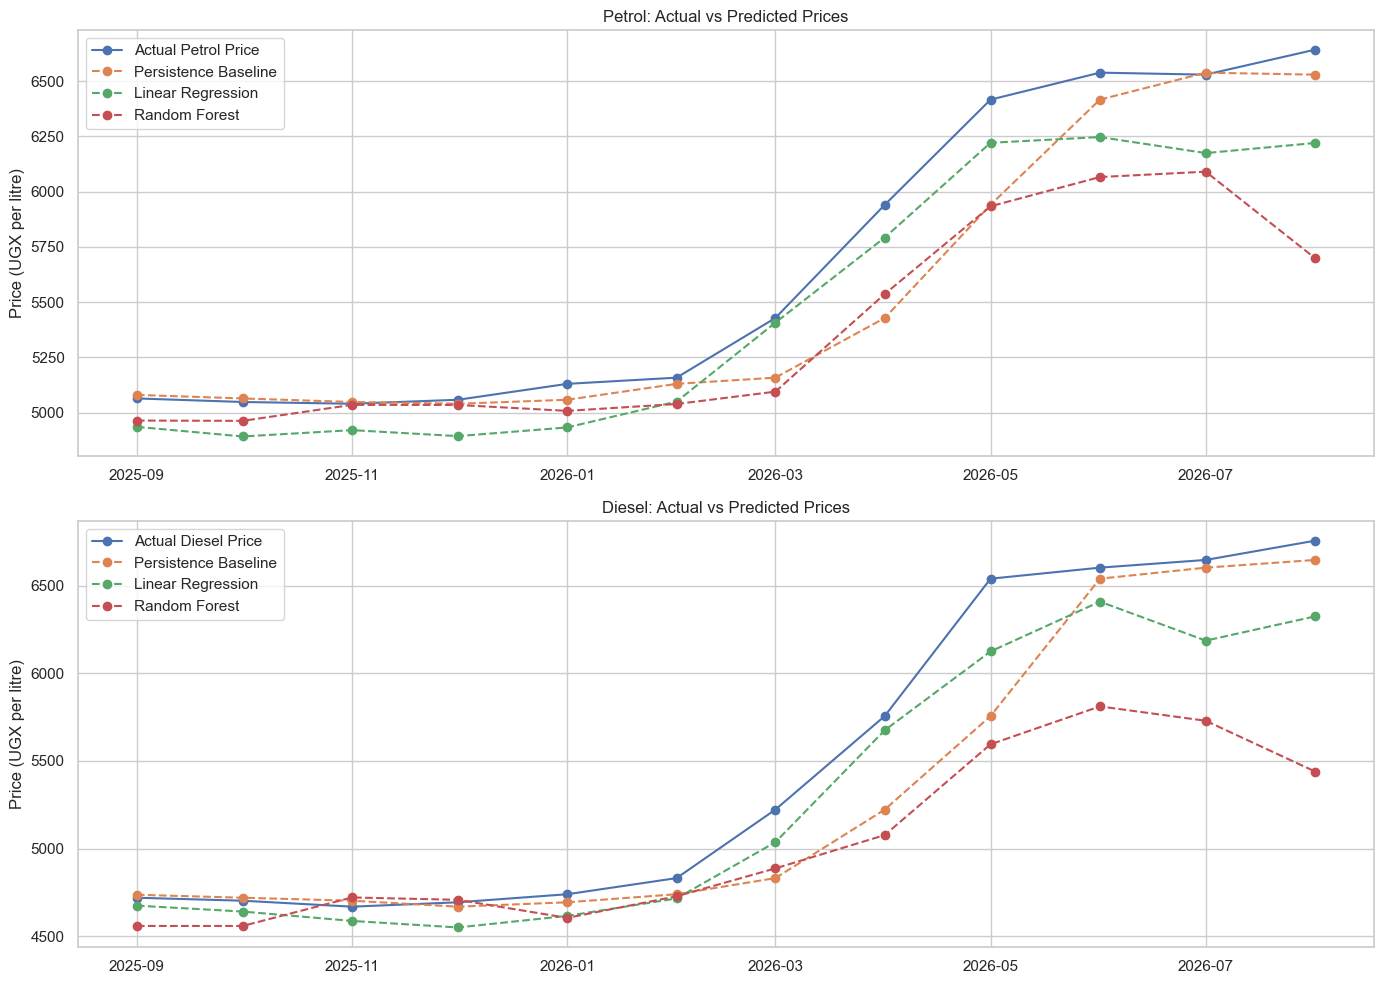

In [86]:
# Petrol forecast comparison
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# PETROL
axes[0].plot(
    petrol_results["Forecast_Origin_Month"],
    petrol_results["Actual_Price"],
    marker="o",
    label="Actual Petrol Price"
)

axes[0].plot(
    petrol_results["Forecast_Origin_Month"],
    petrol_results["Baseline_Prediction"],
    marker="o",
    linestyle="--",
    label="Persistence Baseline"
)

axes[0].plot(
    petrol_results["Forecast_Origin_Month"],
    petrol_results["Linear_Regression"],
    marker="o",
    linestyle="--",
    label="Linear Regression"
)

axes[0].plot(
    petrol_results["Forecast_Origin_Month"],
    petrol_results["Random_Forest"],
    marker="o",
    linestyle="--",
    label="Random Forest"
)

axes[0].set_title("Petrol: Actual vs Predicted Prices")
axes[0].set_ylabel("Price (UGX per litre)")
axes[0].legend()
axes[0].grid(True)

# DIESEL
axes[1].plot(
    diesel_results["Forecast_Origin_Month"],
    diesel_results["Actual_Price"],
    marker="o",
    label="Actual Diesel Price"
)

axes[1].plot(
    diesel_results["Forecast_Origin_Month"],
    diesel_results["Baseline_Prediction"],
    marker="o",
    linestyle="--",
    label="Persistence Baseline"
)

axes[1].plot(
    diesel_results["Forecast_Origin_Month"],
    diesel_results["Linear_Regression"],
    marker="o",
    linestyle="--",
    label="Linear Regression"
)

axes[1].plot(
    diesel_results["Forecast_Origin_Month"],
    diesel_results["Random_Forest"],
    marker="o",
    linestyle="--",
    label="Random Forest"
)

axes[1].set_title("Diesel: Actual vs Predicted Prices")
axes[1].set_ylabel("Price (UGX per litre)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [87]:
# Calculate prediction errors for the test period

for fuel, results in [
    ("PETROL", petrol_results),
    ("DIESEL", diesel_results)
]:

    print(f"\n{fuel} ERROR ANALYSIS")

    for model in [
        "Baseline_Prediction",
        "Linear_Regression",
        "Random_Forest"
    ]:

        errors = (
            results[model] - results["Actual_Price"]
        )

        print(f"\n{model}")
        print("Mean Error:", round(errors.mean(), 2))
        print("Minimum Error:", round(errors.min(), 2))
        print("Maximum Error:", round(errors.max(), 2))


PETROL ERROR ANALYSIS

Baseline_Prediction
Mean Error: -130.17
Minimum Error: -512.0
Maximum Error: 16.0

Linear_Regression
Mean Error: -192.24
Minimum Error: -422.21
Maximum Error: -21.14

Random_Forest
Mean Error: -294.15
Minimum Error: -943.48
Maximum Error: -5.1

DIESEL ERROR ANALYSIS

Baseline_Prediction
Mean Error: -168.42
Minimum Error: -784.0
Maximum Error: 34.0

Linear_Regression
Mean Error: -195.03
Minimum Error: -460.53
Maximum Error: -45.18

Random_Forest
Mean Error: -455.4
Minimum Error: -1317.63
Maximum Error: 52.56


In [88]:
for fuel, results in [
    ("PETROL", petrol_results),
    ("DIESEL", diesel_results)
]:

    print(f"\n{'='*40}")
    print(f"{fuel} ERROR ANALYSIS")
    print(f"{'='*40}")

    for model in [
        "Baseline_Prediction",
        "Linear_Regression",
        "Random_Forest"
    ]:

        errors = results[model] - results["Actual_Price"]

        print(
            f"{model}: "
            f"Mean Error = {errors.mean():.2f}, "
            f"MAE = {errors.abs().mean():.2f}"
        )


PETROL ERROR ANALYSIS
Baseline_Prediction: Mean Error = -130.17, MAE = 138.33
Linear_Regression: Mean Error = -192.24, MAE = 192.24
Random_Forest: Mean Error = -294.15, MAE = 294.15

DIESEL ERROR ANALYSIS
Baseline_Prediction: Mean Error = -168.42, MAE = 179.75
Linear_Regression: Mean Error = -195.03, MAE = 195.03
Random_Forest: Mean Error = -455.40, MAE = 466.51


In [89]:
momentum_results = []

for fuel, X, y, price_column in [
    ("Petrol", X_train_petrol, y_train_petrol,
     "petrol_shs_per_litre"),

    ("Diesel", X_train_diesel, y_train_diesel,
     "diesel_shs_per_litre")
]:

    # Create a dataset containing current price
    # and the previous month's price
    momentum_df = pd.DataFrame({
        "current_price": X[price_column].values,
        "previous_price": X[price_column].shift(1).values,
        "target": y.values
    }).dropna()

    X_momentum = momentum_df[
        ["current_price", "previous_price"]
    ]

    y_momentum = momentum_df["target"]

    fold_baseline_mae = []
    fold_momentum_mae = []

    for train_idx, val_idx in tscv.split(X_momentum):

        X_fold_train = X_momentum.iloc[train_idx]
        X_fold_val = X_momentum.iloc[val_idx]

        y_fold_train = y_momentum.iloc[train_idx]
        y_fold_val = y_momentum.iloc[val_idx]

        # Persistence baseline
        baseline_predictions = (
            X_fold_val["current_price"].values
        )

        # Momentum regression
        model = LinearRegression()

        model.fit(
            X_fold_train,
            y_fold_train
        )

        momentum_predictions = model.predict(
            X_fold_val
        )

        fold_baseline_mae.append(
            mean_absolute_error(
                y_fold_val,
                baseline_predictions
            )
        )

        fold_momentum_mae.append(
            mean_absolute_error(
                y_fold_val,
                momentum_predictions
            )
        )

    momentum_results.extend([
        {
            "Fuel": fuel,
            "Model": "Persistence_Baseline",
            "Average_MAE": np.mean(fold_baseline_mae)
        },
        {
            "Fuel": fuel,
            "Model": "Price_Momentum_Regression",
            "Average_MAE": np.mean(fold_momentum_mae)
        }
    ])

momentum_df_results = pd.DataFrame(momentum_results)

display(momentum_df_results.round(2))

,Fuel,Model,Average_MAE
0,Petrol,Persistence_Baseline,44.67
1,Petrol,Price_Momentum_Regression,42.59
2,Diesel,Persistence_Baseline,48.17
3,Diesel,Price_Momentum_Regression,47.54


In [90]:
# Train final momentum models on the complete training data

momentum_models = {}

for fuel, X, y, price_column in [
    ("Petrol", X_train_petrol, y_train_petrol,
     "petrol_shs_per_litre"),

    ("Diesel", X_train_diesel, y_train_diesel,
     "diesel_shs_per_litre")
]:

    momentum_df = pd.DataFrame({
        "current_price": X[price_column].values,
        "previous_price": X[price_column].shift(1).values,
        "target": y.values
    }).dropna()

    X_momentum = momentum_df[
        ["current_price", "previous_price"]
    ]

    y_momentum = momentum_df["target"]

    model = LinearRegression()

    model.fit(X_momentum, y_momentum)

    momentum_models[fuel] = model

    print(f"\n{fuel} MOMENTUM MODEL")
    print("Intercept:", round(model.intercept_, 4))
    print("Current Price Coefficient:",
          round(model.coef_[0], 4))
    print("Previous Price Coefficient:",
          round(model.coef_[1], 4))


Petrol MOMENTUM MODEL
Intercept: 497.7756
Current Price Coefficient: 1.4883
Previous Price Coefficient: -0.5831

Diesel MOMENTUM MODEL
Intercept: 461.6714
Current Price Coefficient: 1.6034
Previous Price Coefficient: -0.6962


In [91]:
# Prepare common datasets for fair model comparison

common_datasets = {}

for fuel, X, y, price_column in [
    ("Petrol", X_train_petrol, y_train_petrol,
     "petrol_shs_per_litre"),

    ("Diesel", X_train_diesel, y_train_diesel,
     "diesel_shs_per_litre")
]:

    common_df = X.copy()

    common_df["target"] = y.values

    # Previous month's fuel price
    common_df["previous_price"] = (
        common_df[price_column].shift(1)
    )

    # Remove first row because previous price is unavailable
    common_df = common_df.dropna().reset_index(drop=True)

    common_datasets[fuel] = common_df

    print(f"\n{fuel}")
    print("Observations:", len(common_df))
    print("First observation:", common_df.index.min())
    print("Last observation:", common_df.index.max())


Petrol
Observations: 46
First observation: 0
Last observation: 45

Diesel
Observations: 46
First observation: 0
Last observation: 45


In [92]:
common_comparison_results = []

for fuel, df in common_datasets.items():

    price_column = (
        "petrol_shs_per_litre"
        if fuel == "Petrol"
        else "diesel_shs_per_litre"
    )

    feature_sets = {
        "Price_Momentum": [
            price_column,
            "previous_price"
        ],

        "Price_Brent_Lag_3": [
            price_column,
            "brent_lag_3"
        ]
    }

    fold_results = {
        "Persistence_Baseline": {"mae": [], "rmse": []},
        "Price_Momentum": {"mae": [], "rmse": []},
        "Price_Brent_Lag_3": {"mae": [], "rmse": []},
        "Random_Forest": {"mae": [], "rmse": []}
    }

    X = df.drop(columns=["target"])
    y = df["target"]

    for train_idx, val_idx in tscv.split(X):

        X_train_fold = X.iloc[train_idx]
        X_val_fold = X.iloc[val_idx]

        y_train_fold = y.iloc[train_idx]
        y_val_fold = y.iloc[val_idx]

        # 1. Persistence baseline
        predictions = X_val_fold[price_column].values

        fold_results["Persistence_Baseline"]["mae"].append(
            mean_absolute_error(y_val_fold, predictions)
        )

        fold_results["Persistence_Baseline"]["rmse"].append(
            np.sqrt(mean_squared_error(y_val_fold, predictions))
        )

        # 2. Price Momentum and Brent Lag 3
        for model_name, selected_features in feature_sets.items():

            model = LinearRegression()

            model.fit(
                X_train_fold[selected_features],
                y_train_fold
            )

            predictions = model.predict(
                X_val_fold[selected_features]
            )

            fold_results[model_name]["mae"].append(
                mean_absolute_error(y_val_fold, predictions)
            )

            fold_results[model_name]["rmse"].append(
                np.sqrt(mean_squared_error(y_val_fold, predictions))
            )

        # 3. Random Forest
        rf = RandomForestRegressor(
            n_estimators=100,
            max_depth=3,
            min_samples_leaf=3,
            random_state=42
        )

        rf.fit(X_train_fold[[price_column]], y_train_fold)

        predictions = rf.predict(
            X_val_fold[[price_column]]
        )

        fold_results["Random_Forest"]["mae"].append(
            mean_absolute_error(y_val_fold, predictions)
        )

        fold_results["Random_Forest"]["rmse"].append(
            np.sqrt(mean_squared_error(y_val_fold, predictions))
        )

    for model_name, metrics in fold_results.items():

        common_comparison_results.append({
            "Fuel": fuel,
            "Model": model_name,
            "Average_MAE": np.mean(metrics["mae"]),
            "Average_RMSE": np.mean(metrics["rmse"])
        })

common_comparison_df = pd.DataFrame(
    common_comparison_results
)

display(
    common_comparison_df
    .sort_values(["Fuel", "Average_MAE"])
    .round(2)
)

,Fuel,Model,Average_MAE,Average_RMSE
5,Diesel,Price_Momentum,47.54,60.91
4,Diesel,Persistence_Baseline,48.17,57.29
6,Diesel,Price_Brent_Lag_3,69.59,77.76
7,Diesel,Random_Forest,100.65,109.38
1,Petrol,Price_Momentum,42.59,51.97
0,Petrol,Persistence_Baseline,44.67,55.37
2,Petrol,Price_Brent_Lag_3,55.90,64.51
3,Petrol,Random_Forest,84.83,99.18


In [93]:
# Final selected models

final_petrol_model = LinearRegression()

petrol_momentum_train = pd.DataFrame({
    "current_price": X_train_petrol[
        "petrol_shs_per_litre"
    ].values,
    "previous_price": X_train_petrol[
        "petrol_shs_per_litre"
    ].shift(1).values
})

petrol_momentum_train["target"] = y_train_petrol.values

petrol_momentum_train = petrol_momentum_train.dropna()

final_petrol_model.fit(
    petrol_momentum_train[
        ["current_price", "previous_price"]
    ],
    petrol_momentum_train["target"]
)

# Petrol test predictions
petrol_test_momentum = pd.DataFrame({
    "current_price": X_test_petrol[
        "petrol_shs_per_litre"
    ].values,
    "previous_price": X_test_petrol[
        "petrol_shs_per_litre"
    ].shift(1).values
})

# The first test observation needs the final training observation
petrol_test_momentum.iloc[0, 1] = (
    X_train_petrol["petrol_shs_per_litre"].iloc[-1]
)

petrol_momentum_predictions = final_petrol_model.predict(
    petrol_test_momentum
)

# Diesel persistence prediction
diesel_persistence_predictions = (
    X_test_diesel["diesel_shs_per_litre"].values
)

print("Selected models trained and predictions generated.")
print("Petrol momentum predictions:", len(petrol_momentum_predictions))
print("Diesel persistence predictions:", len(diesel_persistence_predictions))

Selected models trained and predictions generated.
Petrol momentum predictions: 12
Diesel persistence predictions: 12


In [94]:
# Evaluate selected models against the persistence baseline

final_results = []

# Petrol: Momentum Regression vs Persistence
for model_name, predictions in [
    ("Petrol Momentum Regression", petrol_momentum_predictions),
    ("Petrol Persistence Baseline", petrol_baseline_predictions)
]:
    actual = y_test_petrol.values

    final_results.append({
        "Fuel": "Petrol",
        "Model": model_name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "MAPE (%)": mean_absolute_percentage_error(
            actual, predictions
        ) * 100,
        "R2": r2_score(actual, predictions),
        "Mean_Error": np.mean(predictions - actual)
    })


# Diesel: Persistence Baseline
actual = y_test_diesel.values
predictions = diesel_persistence_predictions

final_results.append({
    "Fuel": "Diesel",
    "Model": "Diesel Persistence Baseline",
    "MAE": mean_absolute_error(actual, predictions),
    "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
    "MAPE (%)": mean_absolute_percentage_error(
        actual, predictions
    ) * 100,
    "R2": r2_score(actual, predictions),
    "Mean_Error": np.mean(predictions - actual)
})


# Display results
final_test_metrics = pd.DataFrame(final_results)

print("FINAL HOLDOUT TEST RESULTS")
display(final_test_metrics.round(2))

FINAL HOLDOUT TEST RESULTS


,Fuel,Model,MAE,RMSE,MAPE (%),R2,Mean_Error
0,Petrol,Petrol Momentum Regression,110.01,163.76,1.84,0.94,-87.69
1,Petrol,Petrol Persistence Baseline,138.33,222.90,2.32,0.89,-130.17
2,Diesel,Diesel Persistence Baseline,179.75,300.50,3.07,0.88,-168.42


In [95]:
# Train diesel momentum regression

final_diesel_model = LinearRegression()

diesel_momentum_train = pd.DataFrame({
    "current_price": X_train_diesel[
        "diesel_shs_per_litre"
    ].values,
    "previous_price": X_train_diesel[
        "diesel_shs_per_litre"
    ].shift(1).values
})

diesel_momentum_train["target"] = y_train_diesel.values

diesel_momentum_train = diesel_momentum_train.dropna()

final_diesel_model.fit(
    diesel_momentum_train[
        ["current_price", "previous_price"]
    ],
    diesel_momentum_train["target"]
)

# Prepare diesel test predictions
diesel_test_momentum = pd.DataFrame({
    "current_price": X_test_diesel[
        "diesel_shs_per_litre"
    ].values,
    "previous_price": X_test_diesel[
        "diesel_shs_per_litre"
    ].shift(1).values
})

# Use the final training observation for the first test row
diesel_test_momentum.iloc[0, 1] = (
    X_train_diesel["diesel_shs_per_litre"].iloc[-1]
)

diesel_momentum_predictions = final_diesel_model.predict(
    diesel_test_momentum
)

# Evaluate diesel momentum against persistence
actual = y_test_diesel.values

diesel_comparison = pd.DataFrame([
    {
        "Model": "Diesel Momentum Regression",
        "MAE": mean_absolute_error(
            actual, diesel_momentum_predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            actual, diesel_momentum_predictions
        )),
        "MAPE (%)": mean_absolute_percentage_error(
            actual, diesel_momentum_predictions
        ) * 100,
        "R2": r2_score(actual, diesel_momentum_predictions)
    },
    {
        "Model": "Diesel Persistence Baseline",
        "MAE": mean_absolute_error(
            actual, diesel_persistence_predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            actual, diesel_persistence_predictions
        )),
        "MAPE (%)": mean_absolute_percentage_error(
            actual, diesel_persistence_predictions
        ) * 100,
        "R2": r2_score(actual, diesel_persistence_predictions)
    }
])

display(diesel_comparison.round(2))

,Model,MAE,RMSE,MAPE (%),R2
0,Diesel Momentum Regression,165.50,226.11,2.75,0.93
1,Diesel Persistence Baseline,179.75,300.50,3.07,0.88


In [96]:
# Prepare actual vs predicted test results

required_names = {
    "petrol_test",
    "diesel_test",
    "y_test_petrol",
    "y_test_diesel",
    "petrol_momentum_predictions",
    "diesel_persistence_predictions",
}
missing_names = sorted(name for name in required_names if name not in globals())
if missing_names:
    raise RuntimeError(
        "Run the model preparation, train/test split, and final model cells "
        "before this chart cell. Missing: " + ", ".join(missing_names)
    )

if not (
    len(petrol_test) == len(y_test_petrol) == len(petrol_momentum_predictions)
    and len(diesel_test) == len(y_test_diesel) == len(diesel_persistence_predictions)
):
    raise ValueError("Test rows, actual values, and predictions must have matching lengths.")

test_predictions = pd.DataFrame({
    "Month": petrol_test["month"].values,
    "Actual_Petrol": y_test_petrol.values,
    "Predicted_Petrol": petrol_momentum_predictions,
    "Actual_Diesel": y_test_diesel.values,
    "Predicted_Diesel": diesel_persistence_predictions
})

test_predictions["Month"] = pd.to_datetime(
    test_predictions["Month"]
)

# Petrol comparison
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=test_predictions["Month"],
    y=test_predictions["Actual_Petrol"],
    mode="lines+markers",
    name="Actual Petrol"
))

fig.add_trace(go.Scatter(
    x=test_predictions["Month"],
    y=test_predictions["Predicted_Petrol"],
    mode="lines+markers",
    name="Predicted Petrol"
))

fig.update_layout(
    title="Petrol: Actual vs Predicted Prices",
    xaxis_title="Month",
    yaxis_title="Price (UGX per litre)",
    template="plotly_white"
)

fig.show()


# Diesel comparison
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=test_predictions["Month"],
    y=test_predictions["Actual_Diesel"],
    mode="lines+markers",
    name="Actual Diesel"
))

fig.add_trace(go.Scatter(
    x=test_predictions["Month"],
    y=test_predictions["Predicted_Diesel"],
    mode="lines+markers",
    name="Predicted Diesel"
))

fig.update_layout(
    title="Diesel: Actual vs Predicted Prices",
    xaxis_title="Month",
    yaxis_title="Price (UGX per litre)",
    template="plotly_white"
)

fig.show()

In [97]:
# Calculate prediction errors

test_predictions["Petrol_Error"] = (
    test_predictions["Predicted_Petrol"]
    - test_predictions["Actual_Petrol"]
)

test_predictions["Diesel_Error"] = (
    test_predictions["Predicted_Diesel"]
    - test_predictions["Actual_Diesel"]
)

# Display results
display(
    test_predictions[
        [
            "Month",
            "Actual_Petrol",
            "Predicted_Petrol",
            "Petrol_Error",
            "Actual_Diesel",
            "Predicted_Diesel",
            "Diesel_Error"
        ]
    ].round(2)
)

,Month,Actual_Petrol,Predicted_Petrol,Petrol_Error,Actual_Diesel,Predicted_Diesel,Diesel_Error
0,2025-09-01,"5,064.00","5,085.11",21.11,"4,719.00","4,736.00",17.00
1,2025-10-01,"5,048.00","5,072.37",24.37,"4,702.00","4,719.00",17.00
2,2025-11-01,"5,040.00","5,057.89",17.89,"4,668.00","4,702.00",34.00
3,2025-12-01,"5,058.00","5,055.31",-2.69,"4,693.00","4,668.00",-25.00
4,2026-01-01,"5,130.00","5,086.77",-43.23,"4,739.00","4,693.00",-46.00
5,2026-02-01,"5,158.00","5,183.43",25.43,"4,831.00","4,739.00",-92.00
6,2026-03-01,"5,428.00","5,183.12",-244.88,"5,222.00","4,831.00",-391.00
7,2026-04-01,"5,940.00","5,568.64",-371.36,"5,756.00","5,222.00",-534.00
8,2026-05-01,"6,416.00","6,173.22",-242.78,"6,540.00","5,756.00",-784.00
9,2026-06-01,"6,538.00","6,583.11",45.11,"6,603.00","6,540.00",-63.00


In [98]:
# Correct dates to represent the month being predicted

test_predictions["Forecast_Month"] = (
    test_predictions["Month"] + pd.offsets.MonthBegin(1)
)

# Display correctly aligned results

display(
    test_predictions[
        [
            "Forecast_Month",
            "Actual_Petrol",
            "Predicted_Petrol",
            "Petrol_Error",
            "Actual_Diesel",
            "Predicted_Diesel",
            "Diesel_Error"
        ]
    ].round(2)
)

,Forecast_Month,Actual_Petrol,Predicted_Petrol,Petrol_Error,Actual_Diesel,Predicted_Diesel,Diesel_Error
0,2025-10-01,"5,064.00","5,085.11",21.11,"4,719.00","4,736.00",17.00
1,2025-11-01,"5,048.00","5,072.37",24.37,"4,702.00","4,719.00",17.00
2,2025-12-01,"5,040.00","5,057.89",17.89,"4,668.00","4,702.00",34.00
3,2026-01-01,"5,058.00","5,055.31",-2.69,"4,693.00","4,668.00",-25.00
4,2026-02-01,"5,130.00","5,086.77",-43.23,"4,739.00","4,693.00",-46.00
5,2026-03-01,"5,158.00","5,183.43",25.43,"4,831.00","4,739.00",-92.00
6,2026-04-01,"5,428.00","5,183.12",-244.88,"5,222.00","4,831.00",-391.00
7,2026-05-01,"5,940.00","5,568.64",-371.36,"5,756.00","5,222.00",-534.00
8,2026-06-01,"6,416.00","6,173.22",-242.78,"6,540.00","5,756.00",-784.00
9,2026-07-01,"6,538.00","6,583.11",45.11,"6,603.00","6,540.00",-63.00


In [101]:
# Professional Forecast Diagnostics Dashboard

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=[
        "PETROL — Forecast Error Trend",
        "DIESEL — Forecast Error Trend",
        "PETROL — Actual vs Predicted",
        "DIESEL — Actual vs Predicted"
    ],
    vertical_spacing=0.16,
    horizontal_spacing=0.10,
    specs=[
        [{"type": "scatter"}, {"type": "scatter"}],
        [{"type": "scatter"}, {"type": "scatter"}]
    ]
)

dates = test_predictions["Forecast_Month"]

# 1. Petrol residual trend
fig.add_trace(
    go.Scatter(
        x=dates,
        y=test_predictions["Petrol_Error"],
        mode="lines+markers",
        name="Petrol Error",
        line=dict(color="#F59E0B", width=3),
        marker=dict(size=8, symbol="circle"),
        hovertemplate="%{x|%b %Y}<br>Error: %{y:,.0f} UGX<extra></extra>"
    ),
    row=1, col=1
)

# 2. Diesel residual trend
fig.add_trace(
    go.Scatter(
        x=dates,
        y=test_predictions["Diesel_Error"],
        mode="lines+markers",
        name="Diesel Error",
        line=dict(color="#38BDF8", width=3),
        marker=dict(size=8, symbol="circle"),
        hovertemplate="%{x|%b %Y}<br>Error: %{y:,.0f} UGX<extra></extra>"
    ),
    row=1, col=2
)

# Zero reference lines
fig.add_hline(
    y=0, line_dash="dash",
    line_color="#94A3B8", row=1, col=1
)

fig.add_hline(
    y=0, line_dash="dash",
    line_color="#94A3B8", row=1, col=2
)

# 3. Petrol actual vs predicted
fig.add_trace(
    go.Scatter(
        x=dates,
        y=test_predictions["Actual_Petrol"],
        mode="lines+markers",
        name="Actual Petrol",
        line=dict(color="#22C55E", width=3),
        marker=dict(size=6)
    ),
    row=2, col=1
)

fig.add_trace(
    go.Scatter(
        x=dates,
        y=test_predictions["Predicted_Petrol"],
        mode="lines+markers",
        name="Predicted Petrol",
        line=dict(color="#F59E0B", width=3, dash="dot"),
        marker=dict(size=6)
    ),
    row=2, col=1
)

# 4. Diesel actual vs predicted
fig.add_trace(
    go.Scatter(
        x=dates,
        y=test_predictions["Actual_Diesel"],
        mode="lines+markers",
        name="Actual Diesel",
        line=dict(color="#22C55E", width=3),
        marker=dict(size=6)
    ),
    row=2, col=2
)

fig.add_trace(
    go.Scatter(
        x=dates,
        y=test_predictions["Predicted_Diesel"],
        mode="lines+markers",
        name="Predicted Diesel",
        line=dict(color="#38BDF8", width=3, dash="dot"),
        marker=dict(size=6)
    ),
    row=2, col=2
)

# Layout
fig.update_layout(
    title=dict(
        text=(
            "<b>MODEL PERFORMANCE & RESIDUAL DIAGNOSTICS</b>"
            "<br><sup>Petrol and Diesel | Holdout Test Period</sup>"
        ),
        x=0.04,
        font=dict(size=22, color="#F8FAFC")
    ),
    template="plotly_dark",
    paper_bgcolor="#0B1220",
    plot_bgcolor="#111C2E",
    height=850,
    margin=dict(l=70, r=50, t=120, b=80),
    font=dict(family="Arial", color="#CBD5E1", size=11),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.18,
        xanchor="center",
        x=0.5
    ),
    hovermode="x unified"
)

fig.update_xaxes(
    gridcolor="#263449",
    tickformat="%b %Y",
    tickangle=-30
)

fig.update_yaxes(gridcolor="#263449")

fig.update_yaxes(
    title_text="Error (UGX/litre)",
    row=1, col=1
)

fig.update_yaxes(
    title_text="Error (UGX/litre)",
    row=1, col=2
)

fig.update_yaxes(
    title_text="Price (UGX/litre)",
    row=2, col=1
)

fig.update_yaxes(
    title_text="Price (UGX/litre)",
    row=2, col=2
)

fig.show()

In [102]:
# Prepare final petrol and diesel momentum datasets

petrol_final_df = pd.DataFrame({
    "current_price": petrol_model_df[
        "petrol_shs_per_litre"
    ].values,
    "previous_price": petrol_model_df[
        "petrol_shs_per_litre"
    ].shift(1).values,
    "target": petrol_model_df[
        "next_month_petrol"
    ].values
}).dropna()

diesel_final_df = pd.DataFrame({
    "current_price": diesel_model_df[
        "diesel_shs_per_litre"
    ].values,
    "previous_price": diesel_model_df[
        "diesel_shs_per_litre"
    ].shift(1).values,
    "target": diesel_model_df[
        "next_month_diesel"
    ].values
}).dropna()

print("Final training datasets prepared.")

print("Petrol observations:", len(petrol_final_df))
print("Diesel observations:", len(diesel_final_df))

Final training datasets prepared.
Petrol observations: 58
Diesel observations: 58
